# Лексика власти у Фомы Аквинского: сетевой анализ модели *Opera Maiora*

Расчёты к статье «Господство, полномочия, правление: лексика власти у Фомы Аквинского».

**Задача.** Описать контекстное окружение десяти латинских обозначений власти в сочинениях Фомы Аквинского: *dominium, potestas, praelatio, iurisdictio, auctoritas, imperium, principatus, regimen, gubernatio, regnum*.

**Словарь сети.** Для каждой целевой леммы берутся 15 ближайших соседей по косинусному сходству в опубликованной модели *Opera Maiora* (проект LiLa). Целевые леммы и их соседи образуют словарь основной сети. Для соседей дальнейший поиск не выполняется.

**Сеть и сообщества.** Ребро соединяет две леммы, если их косинусное сходство не ниже порога. Порог — наибольшее значение на сетке 0,30–0,80 (шаг 0,01), при котором сеть остаётся связной. Алгоритм Лейдена запускается 50 раз; для таблиц и рисунков берётся медоид — реально полученное разбиение, наиболее близкое к остальным.

**Проверки.** Число соседей меняется на 10 и 20; порог повышается на 0,01; сеть строится по другому правилу отбора рёбер (ближайшие соседи вместо порога); из сети исключаются редкие леммы; десять целевых векторов группируются иерархической кластеризацией.

**Результаты** записываются в `tables/` (CSV, UTF-8) и `figures/` (PNG, 300 dpi). Ячейки выполняются последовательно.

## 1. Подготовка среды

In [19]:
import importlib.util, subprocess, sys

REQUIRED = {                 # имя модуля : имя пакета для установки
    "gensim": "gensim",
    "igraph": "igraph",
    "leidenalg": "leidenalg",
    "seaborn": "seaborn",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "adjustText": "adjustText",
}
missing = [pkg for module, pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]

if missing:
    print("Устанавливаются библиотеки:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("Все необходимые библиотеки уже установлены.")

Все необходимые библиотеки уже установлены.


## 2. Параметры, модель и целевые леммы

Десять лемм заданы в `TARGET_TERMS`. Основная сеть строится при `TOP_N = 15`. `SEED = 42` фиксирует расположение узлов на рисунках и разбиение локальных сетей. Для основной сети выполняются 50 запусков Лейдена с начальными значениями 0–49.

In [20]:
import hashlib, os, urllib.request
from itertools import combinations

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
import seaborn as sns
from adjustText import adjust_text
import igraph as ig
import leidenalg
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import adjusted_rand_score
from gensim.models import KeyedVectors
from gensim.models.fasttext import load_facebook_model
from IPython.display import display, Markdown

# --- Параметры исследования ---------------------------------------------------
SEED = 42                     # раскладка рисунков и локальные сети
TOP_N = 15                    # число ближайших соседей целевой леммы в основной сети
TOP_N_VALUES = (10, 15, 20)   # варианты числа соседей при проверке устойчивости
N_LEIDEN_RUNS = 50            # запусков Лейдена на каждом варианте сети
THRESHOLD_GRID = np.round(np.arange(0.30, 0.801, 0.01), 2)   # проверяемые пороги
LOCAL_FIRST, LOCAL_SECOND = 6, 4                             # схема локальных сетей 6–4
KNN_K = 8                     # число ближайших соседей в сети без порога (раздел 14.1)
MIN_FREQ = 10                 # граница частоты при исключении редких лемм (раздел 14.2)

# --- Каталоги -----------------------------------------------------------------
# При запуске из notebooks/ результаты сохраняются в корне репозитория,
# при запуске из другого места — в текущем рабочем каталоге.
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
MODEL_DIR = os.path.join(ROOT, "models")
FIG_DIR = os.path.join(ROOT, "figures")
TBL_DIR = os.path.join(ROOT, "tables")
for folder in (MODEL_DIR, FIG_DIR, TBL_DIR):
    os.makedirs(folder, exist_ok=True)

# --- Десять целевых лемм (орфография словаря модели: u вместо v) ---------------
TARGET_TERMS = ["dominium", "potestas", "praelatio", "iurisdictio", "auctoritas",
                "imperium", "principatus", "regimen", "gubernatio", "regnum"]
TARGET_PAIRS = list(combinations(TARGET_TERMS, 2))     # все 45 пар целевых лемм

MODEL = {"file": os.path.join(MODEL_DIR, "opera-maiora-lemmas_skip_100.bin"),
         "url": "https://embeddings.lila-erc.eu/samples/download/OperaMaiora/opera-maiora-lemmas_skip_100.bin",
         "sha256": "4f973ddb57a9a382b13345c72269c628f10bae1b4b279f26dca9168697b44f5c"}

# --- Оформление рисунков --------------------------------------------------------
FIG_DPI = 300                 # разрешение сохраняемых PNG
TITLE_SIZE = 16               # заголовки всех рисунков сетей
EDGE_COLOR = "#555555"        # рёбра и контуры обычных узлов
LABEL_COLOR = "#171717"       # подписи узлов
NETWORK_FONT = {"target": 16}                   # общая сеть: подписаны только целевые леммы
COMMUNITY_FONT = {"target": 14, "other": 11}    # отдельные сообщества
LOCAL_FONT = {0: 24, 1: 17, 2: 14}              # локальные сети: целевая лемма, 1-й и 2-й уровень
HEATMAP_CMAP = "Greens"       # матрицы совместной принадлежности

sns.set_style("white")
plt.rcParams.update({
    "figure.dpi": 120, "font.family": "DejaVu Sans", "font.size": 12,
    "axes.titlesize": TITLE_SIZE, "axes.labelsize": 13, "xtick.labelsize": 11,
    "ytick.labelsize": 11, "legend.fontsize": 11,
    "figure.facecolor": "white", "savefig.facecolor": "white",
})
np.random.seed(SEED)


def load_lila_model(info):
    # Загружает двоичную модель fastText проекта LiLa и возвращает векторы её словаря
    # (с частотами лемм) и параметры обучения. Используются только леммы словаря модели.
    if not os.path.exists(info["file"]):
        print(f"Загружается {os.path.basename(info['file'])} (около 770 МБ)…")
        urllib.request.urlretrieve(info["url"], info["file"])
    digest = hashlib.sha256()
    with open(info["file"], "rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            digest.update(chunk)
    if info.get("sha256") and digest.hexdigest() != info["sha256"]:
        raise ValueError("Контрольная сумма не совпадает: это другая версия модели.")
    print(f"{os.path.basename(info['file'])}: SHA-256 {digest.hexdigest()}")

    model = load_facebook_model(info["file"])
    keys = model.wv.index_to_key
    kv = KeyedVectors(vector_size=model.wv.vector_size)
    kv.add_vectors(keys, model.wv.vectors[:len(keys)])
    for k in keys:
        kv.set_vecattr(k, "count", model.wv.get_vecattr(k, "count"))
    params = {"Архитектура": "skip-gram" if model.sg else "CBOW",
              "Размерность векторов": model.wv.vector_size, "Контекстное окно": model.window,
              "Минимальная частота": model.min_count, "Эпох обучения": model.epochs,
              "Отрицательных примеров": model.negative,
              "Длина n-грамм символов": f"{model.wv.min_n}–{model.wv.max_n}",
              "Лемм в словаре": len(keys),
              "Словоупотреблений в корпусе": f"{model.corpus_total_words:,}".replace(",", " ")}
    del model
    return kv, params


wv, MODEL_PARAMS = load_lila_model(MODEL)
absent = [t for t in TARGET_TERMS if t not in wv.key_to_index]
if absent:
    raise ValueError("В словаре модели нет лемм: " + ", ".join(absent))


def freq(word):
    # Частота леммы в обучающем корпусе (по словарю модели).
    return int(wv.get_vecattr(word, "count"))


print(f"Модель загружена: {len(wv)} лемм; целевых лемм: {len(TARGET_TERMS)}")
display(pd.DataFrame(MODEL_PARAMS.items(), columns=["Параметр модели", "Значение"]).set_index("Параметр модели"))
display(Markdown("**Десять целевых лемм**"))
display(pd.DataFrame([{"Лемма": t, "Частота": freq(t)} for t in TARGET_TERMS]).set_index("Лемма"))

opera-maiora-lemmas_skip_100.bin: SHA-256 4f973ddb57a9a382b13345c72269c628f10bae1b4b279f26dca9168697b44f5c
Модель загружена: 6724 лемм; целевых лемм: 10


,Значение
Параметр модели,
Архитектура,skip-gram
Размерность векторов,100
Контекстное окно,10
Минимальная частота,5
Эпох обучения,5
Отрицательных примеров,25
Длина n-грамм символов,3–6
Лемм в словаре,6724
Словоупотреблений в корпусе,4 346 955


**Десять целевых лемм**

,Частота
Лемма,
dominium,287
potestas,2527
praelatio,249
iurisdictio,97
auctoritas,1363
imperium,449
principatus,160
regimen,189
gubernatio,248


## 3. Вспомогательные функции

Функции построения сетей, выделения сообществ, выбора медоида и рисования. Все рисунки сетей используют общие правила: цвет узла — сообщество, толщина и насыщенность ребра — косинусное сходство, целевые леммы набраны прописными буквами и обведены чёрным контуром.

In [21]:
# ---------------------------------------------------------------------------
# Сохранение результатов
# ---------------------------------------------------------------------------
def save_figure(fig, name, folder=FIG_DIR):
    # Показывает рисунок в ноутбуке и сохраняет его в PNG с разрешением FIG_DPI.
    os.makedirs(folder, exist_ok=True)
    fig.savefig(os.path.join(folder, name + ".png"), dpi=FIG_DPI,
                bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def save_table(df, name):
    # Сохраняет таблицу в tables/ в кодировке UTF-8.
    df.to_csv(os.path.join(TBL_DIR, name + ".csv"), encoding="utf-8-sig")


# ---------------------------------------------------------------------------
# Словарь, сходство и сети
# ---------------------------------------------------------------------------
def network_lemmas(top_n):
    # Целевые леммы и top_n ближайших соседей каждой из них.
    lemmas = set(TARGET_TERMS)
    for term in TARGET_TERMS:
        lemmas.update(w for w, _ in wv.most_similar(term, topn=top_n))
    return sorted(lemmas)


def similarity_matrix(lemmas):
    # Косинусное сходство всех пар лемм списка.
    v = np.array([wv[w] for w in lemmas], dtype=np.float64)
    v /= np.linalg.norm(v, axis=1, keepdims=True)
    return v @ v.T


def build_network(lemmas, similarity, threshold):
    # Соединяет ребром каждую пару лемм, косинусное сходство которых не ниже порога.
    rows, cols = np.triu_indices(len(lemmas), k=1)
    weights = similarity[rows, cols]
    keep = weights >= threshold
    graph = nx.Graph()
    graph.add_nodes_from(lemmas)
    for i, j, w in zip(rows[keep], cols[keep], weights[keep]):
        graph.add_edge(lemmas[i], lemmas[j], weight=float(w))
    return graph


def build_knn_network(lemmas, similarity, k):
    # Соединяет каждую лемму с её k ближайшими соседями внутри списка.
    # Ребро проводится, если хотя бы одна из двух лемм входит в число
    # ближайших соседей другой; вес ребра — косинусное сходство.
    n = len(lemmas)
    s = np.asarray(similarity, dtype=float).copy()
    np.fill_diagonal(s, -np.inf)
    ids = np.arange(n)
    chosen = np.zeros((n, n), dtype=bool)
    for i in range(n):
        chosen[i, np.lexsort((ids, -s[i]))[:k]] = True   # при равенстве — по порядку лемм
    keep = chosen | chosen.T
    graph = nx.Graph()
    graph.add_nodes_from(lemmas)
    for i, j in zip(*np.where(np.triu(keep, k=1))):
        graph.add_edge(lemmas[i], lemmas[j], weight=float(similarity[i, j]),
                       mutual=bool(chosen[i, j] and chosen[j, i]))
    return graph


def connectivity_threshold(lemmas, similarity):
    # Наибольший порог сетки, при котором сеть остаётся связной.
    connected = [t for t in THRESHOLD_GRID
                 if nx.is_connected(build_network(lemmas, similarity, float(t)))]
    return float(max(connected))


# ---------------------------------------------------------------------------
# Сообщества и медоид
# ---------------------------------------------------------------------------
def number_communities(membership):
    # Сообщества нумеруются в порядке целевых лемм (сообщество dominium — 1 и т. д.),
    # поэтому номера и цвета не меняются от запуска к запуску.
    new = {}
    for t in TARGET_TERMS:
        if t in membership:
            new.setdefault(membership[t], len(new) + 1)
    for c in sorted(set(membership.values())):
        new.setdefault(c, len(new) + 1)
    return {w: new[c] for w, c in membership.items()}


def leiden(graph, seed=SEED):
    # Алгоритм Лейдена с оптимизацией взвешенной модулярности (вес ребра — косинусное сходство).
    # Возвращает словарь «лемма → номер сообщества» и модулярность Q.
    lemmas = list(graph.nodes)
    index = {w: i for i, w in enumerate(lemmas)}
    g = ig.Graph(n=len(lemmas), edges=[(index[u], index[v]) for u, v in graph.edges])
    weights = [graph[u][v]["weight"] for u, v in graph.edges]
    part = leidenalg.find_partition(g, leidenalg.ModularityVertexPartition,
                                    weights=weights, seed=int(seed))
    membership = {lemmas[i]: c for i, c in enumerate(part.membership)}
    return number_communities(membership), g.modularity(part.membership, weights=weights)


def co_membership(runs):
    # Число запусков, в которых две целевые леммы входят в одно сообщество.
    counts = pd.DataFrame(0, index=TARGET_TERMS, columns=TARGET_TERMS)
    for membership, _ in runs:
        labels = np.array([membership[t] for t in TARGET_TERMS])
        counts += (labels[:, None] == labels[None, :]).astype(int)
    return counts


def partition_medoid(graph, runs):
    # Выбирает из серии запусков реально полученное разбиение, наиболее близкое к остальным.
    # Расстояние между разбиениями — доля пар узлов, для которых не совпадает ответ
    # «в одном сообществе или в разных». При равенстве выбирается разбиение
    # с модулярностью, ближайшей к медиане, затем с меньшим номером запуска.
    nodes = list(graph.nodes())
    i, j = np.triu_indices(len(nodes), k=1)
    signatures = np.array([
        np.array([m[node] for node in nodes])[i] == np.array([m[node] for node in nodes])[j]
        for m, _ in runs
    ], dtype=bool)
    distances = np.abs(signatures - signatures.mean(axis=0)).mean(axis=1)
    q_values = np.array([q for _, q in runs], dtype=float)
    q_median = float(np.median(q_values))
    selected = min(range(len(runs)),
                   key=lambda k: (round(float(distances[k]), 12),
                                  abs(float(q_values[k]) - q_median), k))
    return selected, distances


def analyse_network(graph):
    # 50 запусков Лейдена, медоидное разбиение и совместная принадлежность целевых лемм.
    runs = [leiden(graph, seed=s) for s in range(N_LEIDEN_RUNS)]
    medoid, distances = partition_medoid(graph, runs)
    membership, modularity = runs[medoid]
    return {"graph": graph, "runs": runs, "medoid_seed": medoid,
            "medoid_distance": float(distances[medoid]), "membership": membership,
            "Q": float(modularity), "together": co_membership(runs)}


def community_colors(membership):
    # Цвета сообществ: одна палитра для всех рисунков пороговых и k-NN сетей.
    groups = sorted(set(membership.values()))
    palette = sns.color_palette("tab10" if len(groups) <= 10 else "tab20", len(groups))
    return {c: palette[i] for i, c in enumerate(groups)}


# ---------------------------------------------------------------------------
# Локальные сети по схеме 6–4
# ---------------------------------------------------------------------------
def local_network_6_4(seed_lemma, first=LOCAL_FIRST, second=LOCAL_SECOND):
    # Целевая лемма → её 6 ближайших соседей (первый уровень)
    # → по 4 ближайших соседа каждого из них (второй уровень).
    graph = nx.Graph()
    graph.add_node(seed_lemma, level=0)
    for word1, sim1 in wv.most_similar(seed_lemma, topn=first):
        graph.add_node(word1, level=1)
        graph.add_edge(seed_lemma, word1, weight=float(sim1), relation="first")
        candidates = [(w, s) for w, s in wv.most_similar(word1, topn=second + 10)
                      if w != seed_lemma][:second]
        for word2, sim2 in candidates:
            if word2 not in graph:
                graph.add_node(word2, level=2)
            if not graph.has_edge(word1, word2):
                graph.add_edge(word1, word2, weight=float(sim2), relation="second")
    return graph


# ---------------------------------------------------------------------------
# Общие элементы рисунков сетей
# ---------------------------------------------------------------------------
def orient(positions, anchor):
    # Отражает раскладку так, чтобы указанная лемма оказалась слева внизу:
    # рисунки остаются сопоставимыми между запусками.
    xs = np.array([p[0] for p in positions.values()])
    ys = np.array([p[1] for p in positions.values()])
    x_mid, y_mid = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2
    fx = 1 if positions[anchor][0] <= x_mid else -1
    fy = 1 if positions[anchor][1] <= y_mid else -1
    return {n: ((p[0] - x_mid) * fx + x_mid, (p[1] - y_mid) * fy + y_mid)
            for n, p in positions.items()}


def layout(graph, anchor, k, iterations=500):
    return orient(nx.spring_layout(graph, k=k, iterations=iterations, weight="weight", seed=SEED), anchor)


def draw_edges(ax, graph, pos, width, alpha, top=None, extra=None):
    # Толщина и насыщенность ребра растут с косинусным сходством.
    # width и alpha — пары (минимум, прирост); top — сходство, принимаемое за максимум
    # (по умолчанию наибольшее в графе); extra — добавка к толщине для отдельных рёбер.
    weights = [d["weight"] for _, _, d in graph.edges(data=True)]
    if not weights:
        return
    low = min(weights)
    span = max((max(weights) if top is None else top) - low, 1e-6)
    for u, v, d in graph.edges(data=True):
        f = (d["weight"] - low) / span
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color=EDGE_COLOR,
                alpha=alpha[0] + alpha[1] * f,
                linewidth=width[0] + width[1] * f + (extra(d) if extra else 0.0), zorder=1)


def draw_label(ax, xy, text, size, bold, outline):
    label = ax.text(*xy, text, fontsize=size, fontweight="bold" if bold else "normal",
                    ha="center", va="center", zorder=6, color=LABEL_COLOR)
    label.set_path_effects([pe.withStroke(linewidth=outline, foreground="white")])
    return label


def finish_network(ax, title):
    ax.set_title(title, fontsize=TITLE_SIZE, pad=16)
    ax.axis("off")


# ---------------------------------------------------------------------------
# Рисунок сети целиком (основная сеть и сеть ближайших соседей)
# ---------------------------------------------------------------------------
def draw_network(graph, membership, title):
    # Подписаны только целевые леммы; adjustText разводит подписи, не меняя положения узлов.
    colors = community_colors(membership)
    pos = layout(graph, TARGET_TERMS[0], k=1.2)
    fig, ax = plt.subplots(figsize=(20, 15))
    draw_edges(ax, graph, pos, width=(0.45, 1.20), alpha=(0.15, 0.28), top=1.0)
    for node in graph.nodes:
        target = node in TARGET_TERMS
        ax.scatter(*pos[node], s=2050 if target else 280, c=[colors[membership[node]]],
                   alpha=0.92, zorder=3, edgecolors="black" if target else EDGE_COLOR,
                   linewidths=2.2 if target else 0.5)
    labels = [draw_label(ax, pos[t], t.upper(), NETWORK_FONT["target"], True, 4.0)
              for t in TARGET_TERMS]

    legend = [Line2D([0], [0], marker="o", color="w", label=label, markerfacecolor="white",
                     markeredgecolor="black", markeredgewidth=width, markersize=size)
              for label, width, size in [("Целевая лемма", 2.2, 18), ("Ближайший сосед", 0.5, 9)]]
    for c in sorted(colors):
        targets = [t for t in TARGET_TERMS if membership[t] == c]
        legend.append(mpatches.Patch(
            facecolor=colors[c], edgecolor="#333333",
            label=f"Сообщество {c}" + (f" ({', '.join(targets)})" if targets else "")))
    ax.legend(handles=legend, loc="upper left", bbox_to_anchor=(1.0, 1.0), framealpha=0.96,
              title="Обозначения", title_fontsize=13,
              borderpad=1, labelspacing=0.9, fontsize=10.5)
    ax.margins(x=0.17, y=0.17)          # место для смещаемых подписей
    finish_network(ax, title)
    adjust_text(labels, ax=ax,
                x=[pos[n][0] for n in graph], y=[pos[n][1] for n in graph],
                target_x=[pos[t][0] for t in TARGET_TERMS],
                target_y=[pos[t][1] for t in TARGET_TERMS],
                force_text=(0.6, 0.9), force_static=(0.12, 0.18),
                force_pull=(0.012, 0.012), expand=(1.12, 1.20),
                ensure_inside_axes=True, iter_lim=350, min_arrow_len=12,
                arrowprops={"arrowstyle": "-", "color": "#777777", "lw": 0.75})
    return fig


# ---------------------------------------------------------------------------
# Рисунок одного сообщества
# ---------------------------------------------------------------------------
def draw_community(graph, membership, community):
    colors = community_colors(membership)
    sub = graph.subgraph([n for n in graph.nodes if membership[n] == community]).copy()
    targets = [t for t in TARGET_TERMS if t in sub]
    anchor = targets[0] if targets else max(sub.degree, key=lambda item: item[1])[0]
    pos = layout(sub, anchor, k=1.6 if sub.number_of_nodes() <= 25 else 1.2)
    fig, ax = plt.subplots(figsize=(15, 11))
    draw_edges(ax, sub, pos, width=(0.8, 2.5), alpha=(0.35, 0.50))
    degree = dict(sub.degree)
    for node in sub.nodes:
        target = node in TARGET_TERMS
        ax.scatter(*pos[node], s=1900 if target else 260 + 22 * degree[node],
                   c=[colors[community]], alpha=0.92, zorder=3,
                   edgecolors="black" if target else EDGE_COLOR,
                   linewidths=2.2 if target else 0.6)
        draw_label(ax, pos[node], node.upper() if target else node,
                   COMMUNITY_FONT["target" if target else "other"], target, 3 if target else 2)
    finish_network(ax, f"Сообщество {community}: {', '.join(targets) or 'без целевых лемм'}\n"
                       f"{sub.number_of_nodes()} лемм · {sub.number_of_edges()} внутренних рёбер")
    return fig, anchor


# ---------------------------------------------------------------------------
# Рисунок локальной сети 6–4
# ---------------------------------------------------------------------------
def draw_local_network(seed_lemma, graph):
    # Цвет узла — группа внутри локальной сети, выделенная алгоритмом Лейдена.
    # Рёбра заданы схемой 6–4, поэтому группы служат только чтению ближайшего окружения.
    group_of, _ = leiden(graph, seed=SEED)
    groups = sorted(set(group_of.values()))
    palette = sns.color_palette("Set2", len(groups))
    colors = {c: palette[i] for i, c in enumerate(groups)}
    pos = layout(graph, seed_lemma, k=1.35, iterations=600)
    fig, ax = plt.subplots(figsize=(15, 11))
    draw_edges(ax, graph, pos, width=(0.8, 2.2), alpha=(0.35, 0.55),
               extra=lambda d: 0.8 if d["relation"] == "first" else 0.0)
    for node in graph.nodes:
        level = graph.nodes[node]["level"]
        ax.scatter(*pos[node], s={0: 4200, 1: 2400, 2: 1000}[level],
                   c=[colors[group_of[node]]], alpha=0.92, zorder=3,
                   edgecolors="black" if level == 0 else EDGE_COLOR,
                   linewidths=2.2 if level == 0 else 1.0)
        draw_label(ax, pos[node], node.upper() if level == 0 else node,
                   LOCAL_FONT[level], level <= 1, 3 if level <= 1 else 2)
    finish_network(ax, f"Локальная сеть {seed_lemma.upper()} по схеме 6–4\n"
                       f"{graph.number_of_nodes()} лемм · {graph.number_of_edges()} рёбер")
    return fig


# ---------------------------------------------------------------------------
# Матрица совместной принадлежности целевых лемм
# ---------------------------------------------------------------------------
def draw_co_membership(counts, order, title, ax=None, colorbar=True):
    # Число запусков из N_LEIDEN_RUNS, в которых две целевые леммы оказались в одном сообществе.
    fig = None
    if ax is None:
        fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(counts.loc[order, order], cmap=HEATMAP_CMAP, vmin=0, vmax=N_LEIDEN_RUNS,
                annot=True, fmt="d", annot_kws={"size": 9}, linewidths=0.4, linecolor="white",
                square=True, cbar=colorbar,
                cbar_kws={"label": f"Запусков из {N_LEIDEN_RUNS}", "shrink": 0.8}, ax=ax)
    ax.set_title(title, pad=15)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    return fig

## 4. Фоновое распределение косинусного сходства

Сходство рассчитывается для всех пар лемм словаря модели. Среднее, стандартное отклонение и перцентили служат шкалой: по ним оценивается положение порога сети (раздел 6) и сходство пар целевых лемм (раздел 11).

,Значение
Показатель,
Число уникальных пар,22 602 726
Среднее,0.2792
Стандартное отклонение,0.1085
95-й перцентиль,0.4642
99-й перцентиль,0.5464


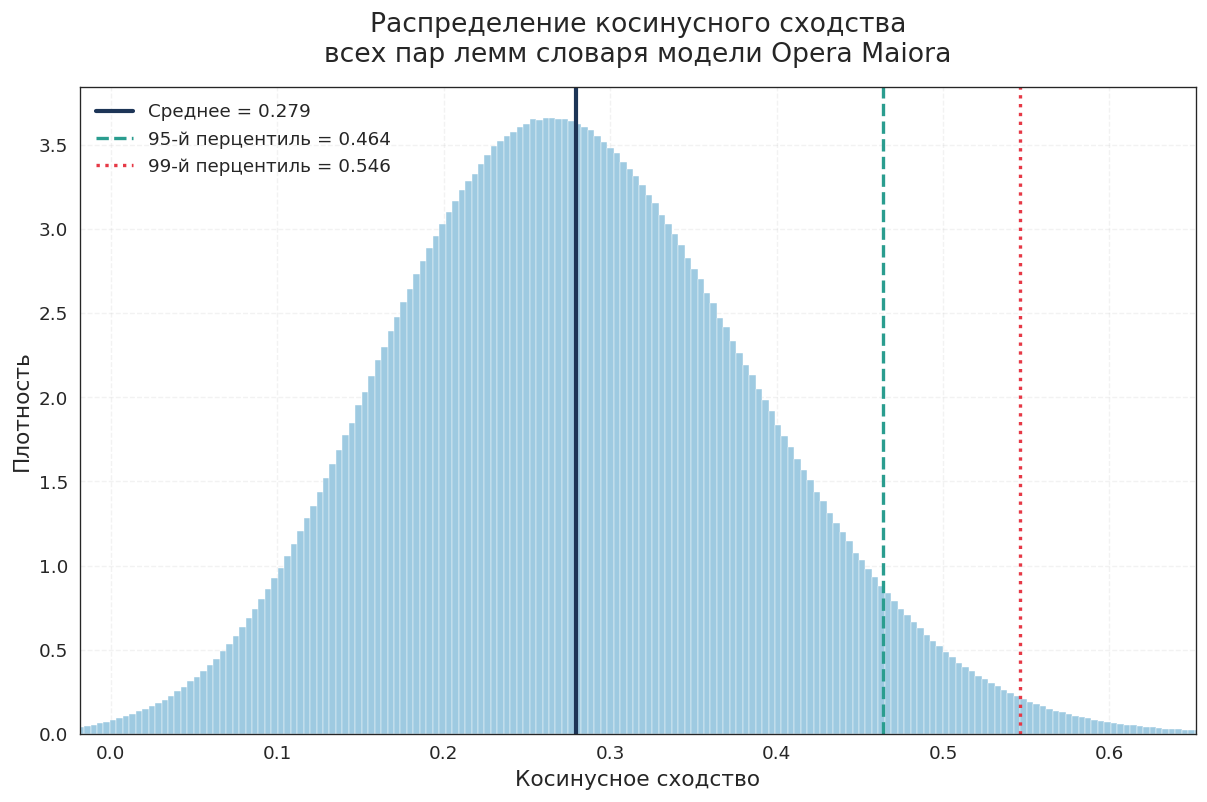

In [22]:
vectors = wv.get_normed_vectors()
parts = []
for start in range(0, len(wv), 1000):            # блоками, чтобы хватило памяти
    block = vectors[start:start + 1000] @ vectors.T
    for i in range(block.shape[0]):
        parts.append(block[i, start + i + 1:])   # каждая пара учитывается один раз
all_similarities = np.concatenate(parts)
del parts

mean_sim, std_sim = float(all_similarities.mean()), float(all_similarities.std())
p95, p99 = np.percentile(all_similarities, [95, 99])

background = pd.DataFrame([
    ("Число уникальных пар", f"{len(all_similarities):,}".replace(",", " ")),
    ("Среднее", f"{mean_sim:.4f}"),
    ("Стандартное отклонение", f"{std_sim:.4f}"),
    ("95-й перцентиль", f"{p95:.4f}"),
    ("99-й перцентиль", f"{p99:.4f}"),
], columns=["Показатель", "Значение"]).set_index("Показатель")
display(background)
save_table(background, "cosine_background")

fig, ax = plt.subplots(figsize=(12, 7))
ax.hist(all_similarities, bins=300, density=True, color="#9ecae1", edgecolor="white", linewidth=0.25)
ax.axvline(mean_sim, color="#1d3557", linewidth=2.5, label=f"Среднее = {mean_sim:.3f}")
ax.axvline(p95, color="#2a9d8f", linewidth=2, linestyle="--", label=f"95-й перцентиль = {p95:.3f}")
ax.axvline(p99, color="#e63946", linewidth=2, linestyle=":", label=f"99-й перцентиль = {p99:.3f}")
ax.set_xlabel("Косинусное сходство")
ax.set_ylabel("Плотность")
ax.set_title("Распределение косинусного сходства\nвсех пар лемм словаря модели Opera Maiora", pad=15)
ax.grid(True, linestyle="--", alpha=0.25)
ax.legend(frameon=False)
ax.set_xlim(*np.percentile(all_similarities, [0.1, 99.9]))
save_figure(fig, "cosine_distribution")
del all_similarities

## 5. Ближайшие соседи и словарь сети

Для каждой целевой леммы отбираются пятнадцать ближайших соседей по косинусному сходству, без тематического или морфологического отбора. Целевые леммы и их соседи образуют словарь сети. Таблица узлов показывает частоту каждой леммы и то, в списках каких целевых лемм она найдена.

In [23]:
neighbours = {term: wv.most_similar(term, topn=TOP_N) for term in TARGET_TERMS}

display(Markdown("**Пятнадцать ближайших соседей десяти целевых лемм**"))
display(pd.DataFrame([
    {"Лемма": term, "Частота": freq(term),
     "Ближайшие соседи (косинусное сходство)": ", ".join(f"{w} {s:.3f}" for w, s in neighbours[term])}
    for term in TARGET_TERMS
]).set_index("Лемма").style.set_properties(**{"text-align": "left", "white-space": "normal"}))

lemmas = network_lemmas(TOP_N)
similarity = similarity_matrix(lemmas)
print(f"Словарь основной сети: {len(lemmas)} лемм, из них целевых {len(TARGET_TERMS)}; "
      f"с частотой ниже {MIN_FREQ}: {sum(freq(w) < MIN_FREQ for w in lemmas)}")

save_table(pd.DataFrame([
    {"Целевая лемма": term, "Ранг": rank, "Сосед": word,
     "Косинусное сходство": float(score), "Частота соседа": freq(word)}
    for term in TARGET_TERMS
    for rank, (word, score) in enumerate(neighbours[term], 1)
]).set_index(["Целевая лемма", "Ранг"]), "top15_neighbors")

save_table(pd.DataFrame([
    {"Лемма": word, "Частота": freq(word),
     "Целевая лемма": "да" if word in TARGET_TERMS else "нет",
     "Найдена среди соседей целевых лемм": ", ".join(
         t for t in TARGET_TERMS if word in {w for w, _ in neighbours[t]}) or "–"}
    for word in lemmas
]).set_index("Лемма"), "network_nodes")

**Пятнадцать ближайших соседей десяти целевых лемм**

,Частота,Ближайшие соседи (косинусное сходство)
Лемма,,
dominium,287,"seruitus 0.684, seruus 0.682, dominor 0.658, coerceo 0.633, potestas 0.632, seruitium 0.615, dominatio 0.611, conseruus 0.599, despoticus 0.595, usurpo 0.593, iurisconsultus 0.593, mercatio 0.584, tyrannicus 0.572, patrimonium 0.570, latrocinium 0.568"
potestas,2527,"iurisdictio 0.665, eximo 0.645, minister 0.643, dominium 0.632, ecclesia 0.628, possum 0.624, episcopatus 0.622, arbiter 0.620, resigno 0.620, sacerdotalis 0.620, ordinatio 0.617, ordinarius 0.617, regalis 0.616, inuincibilis 0.615, iudiciarius 0.614"
praelatio,249,"celatio 0.734, subiectio 0.712, praefero 0.671, uelatio 0.657, plebeius 0.657, ordinatio 0.655, praeficio 0.655, praepono 0.654, ordinarius 0.648, tyrannicus 0.644, officium 0.638, primatus 0.634, procuratio 0.632, is 0.631, episcopatus 0.628"
iurisdictio,97,"degrado 0.761, excommunicatio 0.726, clauis 0.720, forum 0.711, episcopus 0.699, laicus 0.698, absolutio 0.696, parochialis 0.679, subdiaconatus 0.672, indulgentia 0.669, ordinarius 0.669, excommunico 0.667, potestas 0.665, diaconatus 0.662, uicarius 0.660"
auctoritas,1363,"subauctoritas 0.870, auctoritatiuus 0.772, induco 0.695, assertiuus 0.671, solutio 0.668, apostolicus 0.662, declaratio 0.659, tractator 0.654, obiectio 0.653, expositio 0.653, probatio 0.652, ceterum 0.649, aio 0.645, improbatio 0.642, auctor 0.640"
imperium,449,"impero 0.794, imperatiuus 0.727, obedio 0.724, despoticus 0.718, exequor 0.695, nutus 0.646, imperitus 0.639, motiuus 0.631, subiaceo 0.630, regalis 0.616, elicitiuus 0.607, persuasibilis 0.594, uis 0.583, potestas 0.580, ordinatio 0.579"
principatus,160,"dominatio 0.788, principor 0.784, princeps 0.758, despoticus 0.747, prouincia 0.739, archangelus 0.729, dominatiuus 0.720, regalis 0.708, optimas 0.701, aristocratia 0.678, michael 0.665, regnatiuus 0.653, regimen 0.646, tyrannicus 0.631, praesideo 0.629"
regimen,189,"praeficio 0.738, gubernatiuus 0.713, gubernatio 0.705, aristocratia 0.703, optimas 0.696, regitiuus 0.686, ciuitas 0.683, rector 0.668, tyrannicus 0.668, regius 0.665, subdo 0.665, ordinator 0.664, regalis 0.664, ordinatio 0.661, regnatiuus 0.660"
gubernatio,248,"guberno 0.882, gubernatiuus 0.867, gubernator 0.863, gubernatorius 0.781, ordinator 0.762, prouisor 0.733, regimen 0.705, prouidentia 0.705, ordinatio 0.701, coordinatio 0.698, praeficio 0.695, prouisio 0.689, praesideo 0.677, prouidus 0.673, aristocratia 0.671"


Словарь основной сети: 122 лемм, из них целевых 10; с частотой ниже 10: 20


## 6. Выбор порога основной сети

На сетке от 0,30 до 0,80 с шагом 0,01 выбирается наибольшее значение, при котором все узлы входят в одну связную компоненту. Порог определяется до выделения сообществ и не зависит от модулярности.

Выбранный порог θ = 0.59: рёбер 715, плотность 0.097
Порог в стандартных отклонениях от среднего по модели: 2.87; 99-й перцентиль: 0.5464


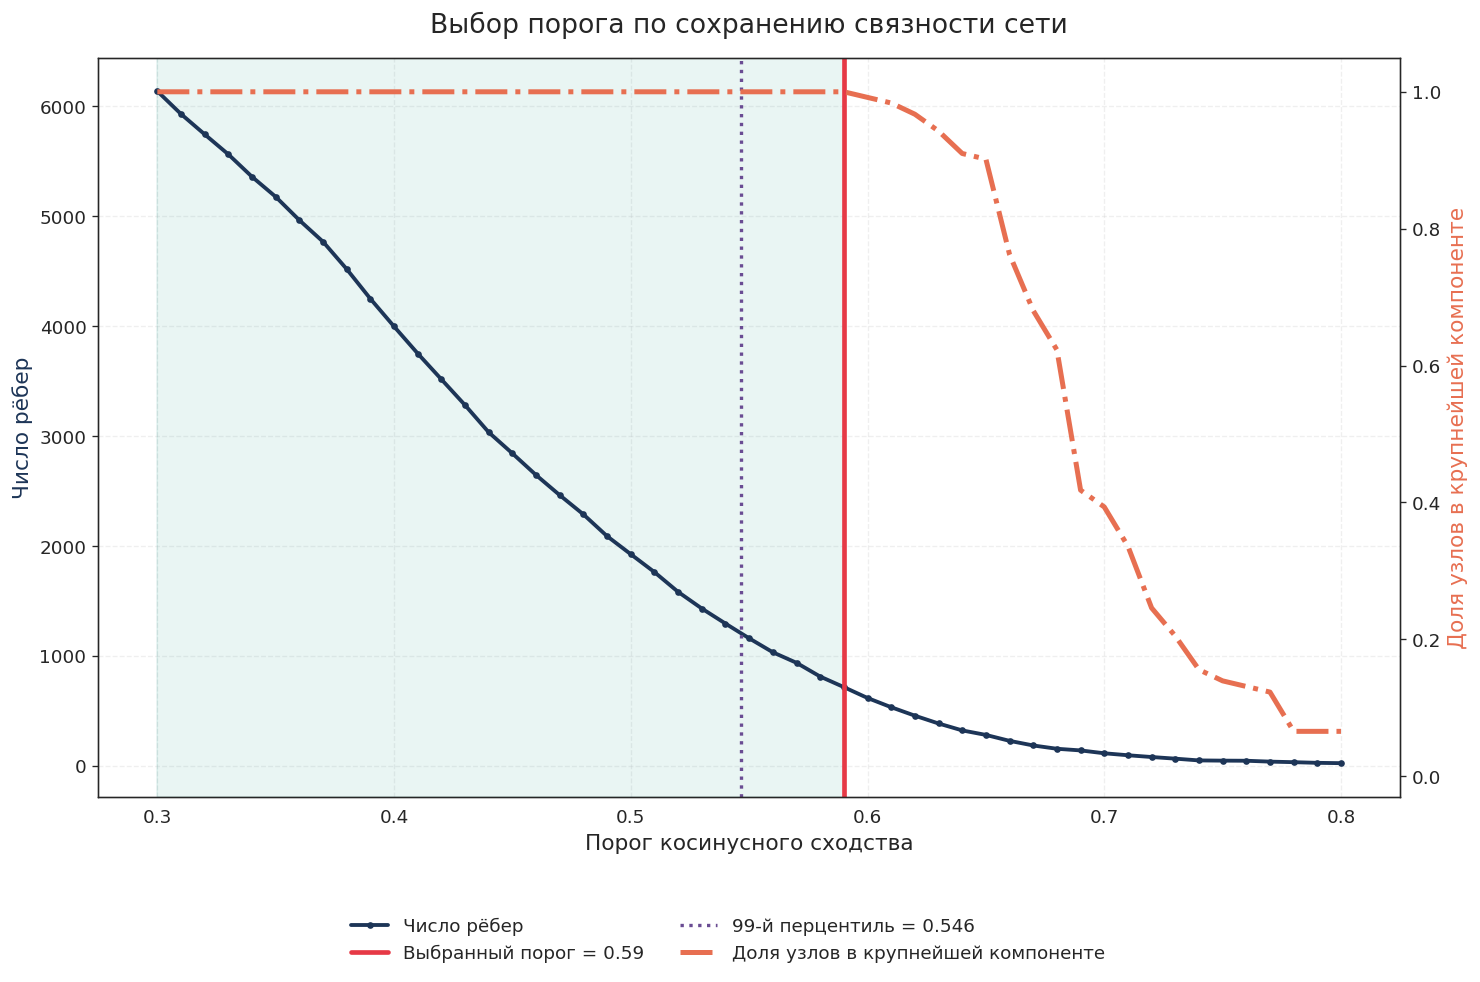

In [24]:
scan = []
for threshold in THRESHOLD_GRID:
    g = build_network(lemmas, similarity, float(threshold))
    largest = max(len(c) for c in nx.connected_components(g))
    scan.append({"Порог": float(threshold), "Рёбер": g.number_of_edges(),
                 "Плотность": nx.density(g),
                 "Компонент": nx.number_connected_components(g),
                 "Доля лемм в крупнейшей компоненте": largest / len(lemmas)})
scan = pd.DataFrame(scan)
save_table(scan.set_index("Порог"), "threshold_scan")

THRESHOLD = float(scan.loc[scan["Компонент"] == 1, "Порог"].max())
chosen = scan.loc[np.isclose(scan["Порог"], THRESHOLD)].iloc[0]
print(f"Выбранный порог θ = {THRESHOLD:.2f}: рёбер {int(chosen['Рёбер'])}, "
      f"плотность {chosen['Плотность']:.3f}")
print(f"Порог в стандартных отклонениях от среднего по модели: {(THRESHOLD - mean_sim) / std_sim:.2f}; "
      f"99-й перцентиль: {p99:.4f}")

fig, ax1 = plt.subplots(figsize=(14, 8))
ax2 = ax1.twinx()
ax1.axvspan(THRESHOLD_GRID[0], THRESHOLD, color="#2a9d8f", alpha=0.10)
ax1.plot(scan["Порог"], scan["Рёбер"], color="#1d3557", marker="o",
         markersize=3, linewidth=2.3, label="Число рёбер")
ax2.plot(scan["Порог"], scan["Доля лемм в крупнейшей компоненте"],
         color="#e76f51", linestyle="-.", linewidth=3,
         label="Доля узлов в крупнейшей компоненте")
ax1.axvline(THRESHOLD, color="#e63946", linewidth=2.8, label=f"Выбранный порог = {THRESHOLD:.2f}")
ax1.axvline(p99, color="#6a4c93", linestyle=":", linewidth=2.0, label=f"99-й перцентиль = {p99:.3f}")
ax1.set_xlabel("Порог косинусного сходства")
ax1.set_ylabel("Число рёбер", color="#1d3557")
ax2.set_ylabel("Доля узлов в крупнейшей компоненте", color="#e76f51")
ax2.set_ylim(-0.03, 1.05)
ax1.grid(True, linestyle="--", alpha=0.3)
ax1.set_title("Выбор порога по сохранению связности сети", pad=15)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.08))
save_figure(fig, "threshold_selection")

## 7. Основная сеть и её сообщества

На построенной сети выполняются 50 запусков алгоритма Лейдена. Медоид выбирается из полученных разбиений по наименьшему среднему расхождению с остальными. Номера сообществ следуют порядку целевых лемм в `TARGET_TERMS` и содержательного значения не имеют.

Основная сеть: 122 лемм, 715 рёбер, θ = 0.59
Медоид из 50 запусков: запуск 0, сообществ 7, Q = 0.4945


**Сообщества основной сети (медоидное разбиение)**

,Целевые леммы,Число лемм,Все леммы сообщества
Сообщество,,,
1,dominium,13,"coerceo, conseruus, dominium, dominor, iurisconsultus, latrocinium, mercatio, plebeius, seruitium, seruitus, seruus, subiectio, usurpo"
2,"potestas, praelatio, iurisdictio",34,"absolutio, arbiter, celatio, clauis, degrado, diaconatus, ecclesia, episcopatus, episcopus, excommunicatio, excommunico, eximo, forum, indulgentia, inuincibilis, is, iudiciarius, iurisdictio, laicus, minister, officium, ordinarius, parochialis, patrimonium, possum, potestas, praefero, praelatio, procuratio, resigno, sacerdotalis, subdiaconatus, uelatio, uicarius"
3,auctoritas,16,"aio, apostolicus, assertiuus, auctor, auctoritas, auctoritatiuus, ceterum, declaratio, expositio, improbatio, induco, obiectio, probatio, solutio, subauctoritas, tractator"
4,imperium,11,"elicitiuus, exequor, imperatiuus, imperitus, imperium, impero, motiuus, nutus, obedio, persuasibilis, uis"
5,"principatus, regimen",23,"archangelus, aristocratia, ciuitas, despoticus, dominatio, dominatiuus, michael, optimas, persa, praepono, primatus, princeps, principatus, principor, prouincia, rector, regalis, regimen, regitiuus, regius, regnatiuus, rex, tyrannicus"
6,gubernatio,16,"coordinatio, gubernatio, gubernatiuus, gubernator, gubernatorius, guberno, ordinatio, ordinator, praeficio, praesideo, prouidentia, prouidus, prouisio, prouisor, subdo, subiaceo"
7,regnum,9,"aperio, iechonias, ierusalem, introeo, introitus, intromitto, possideo, regno, regnum"


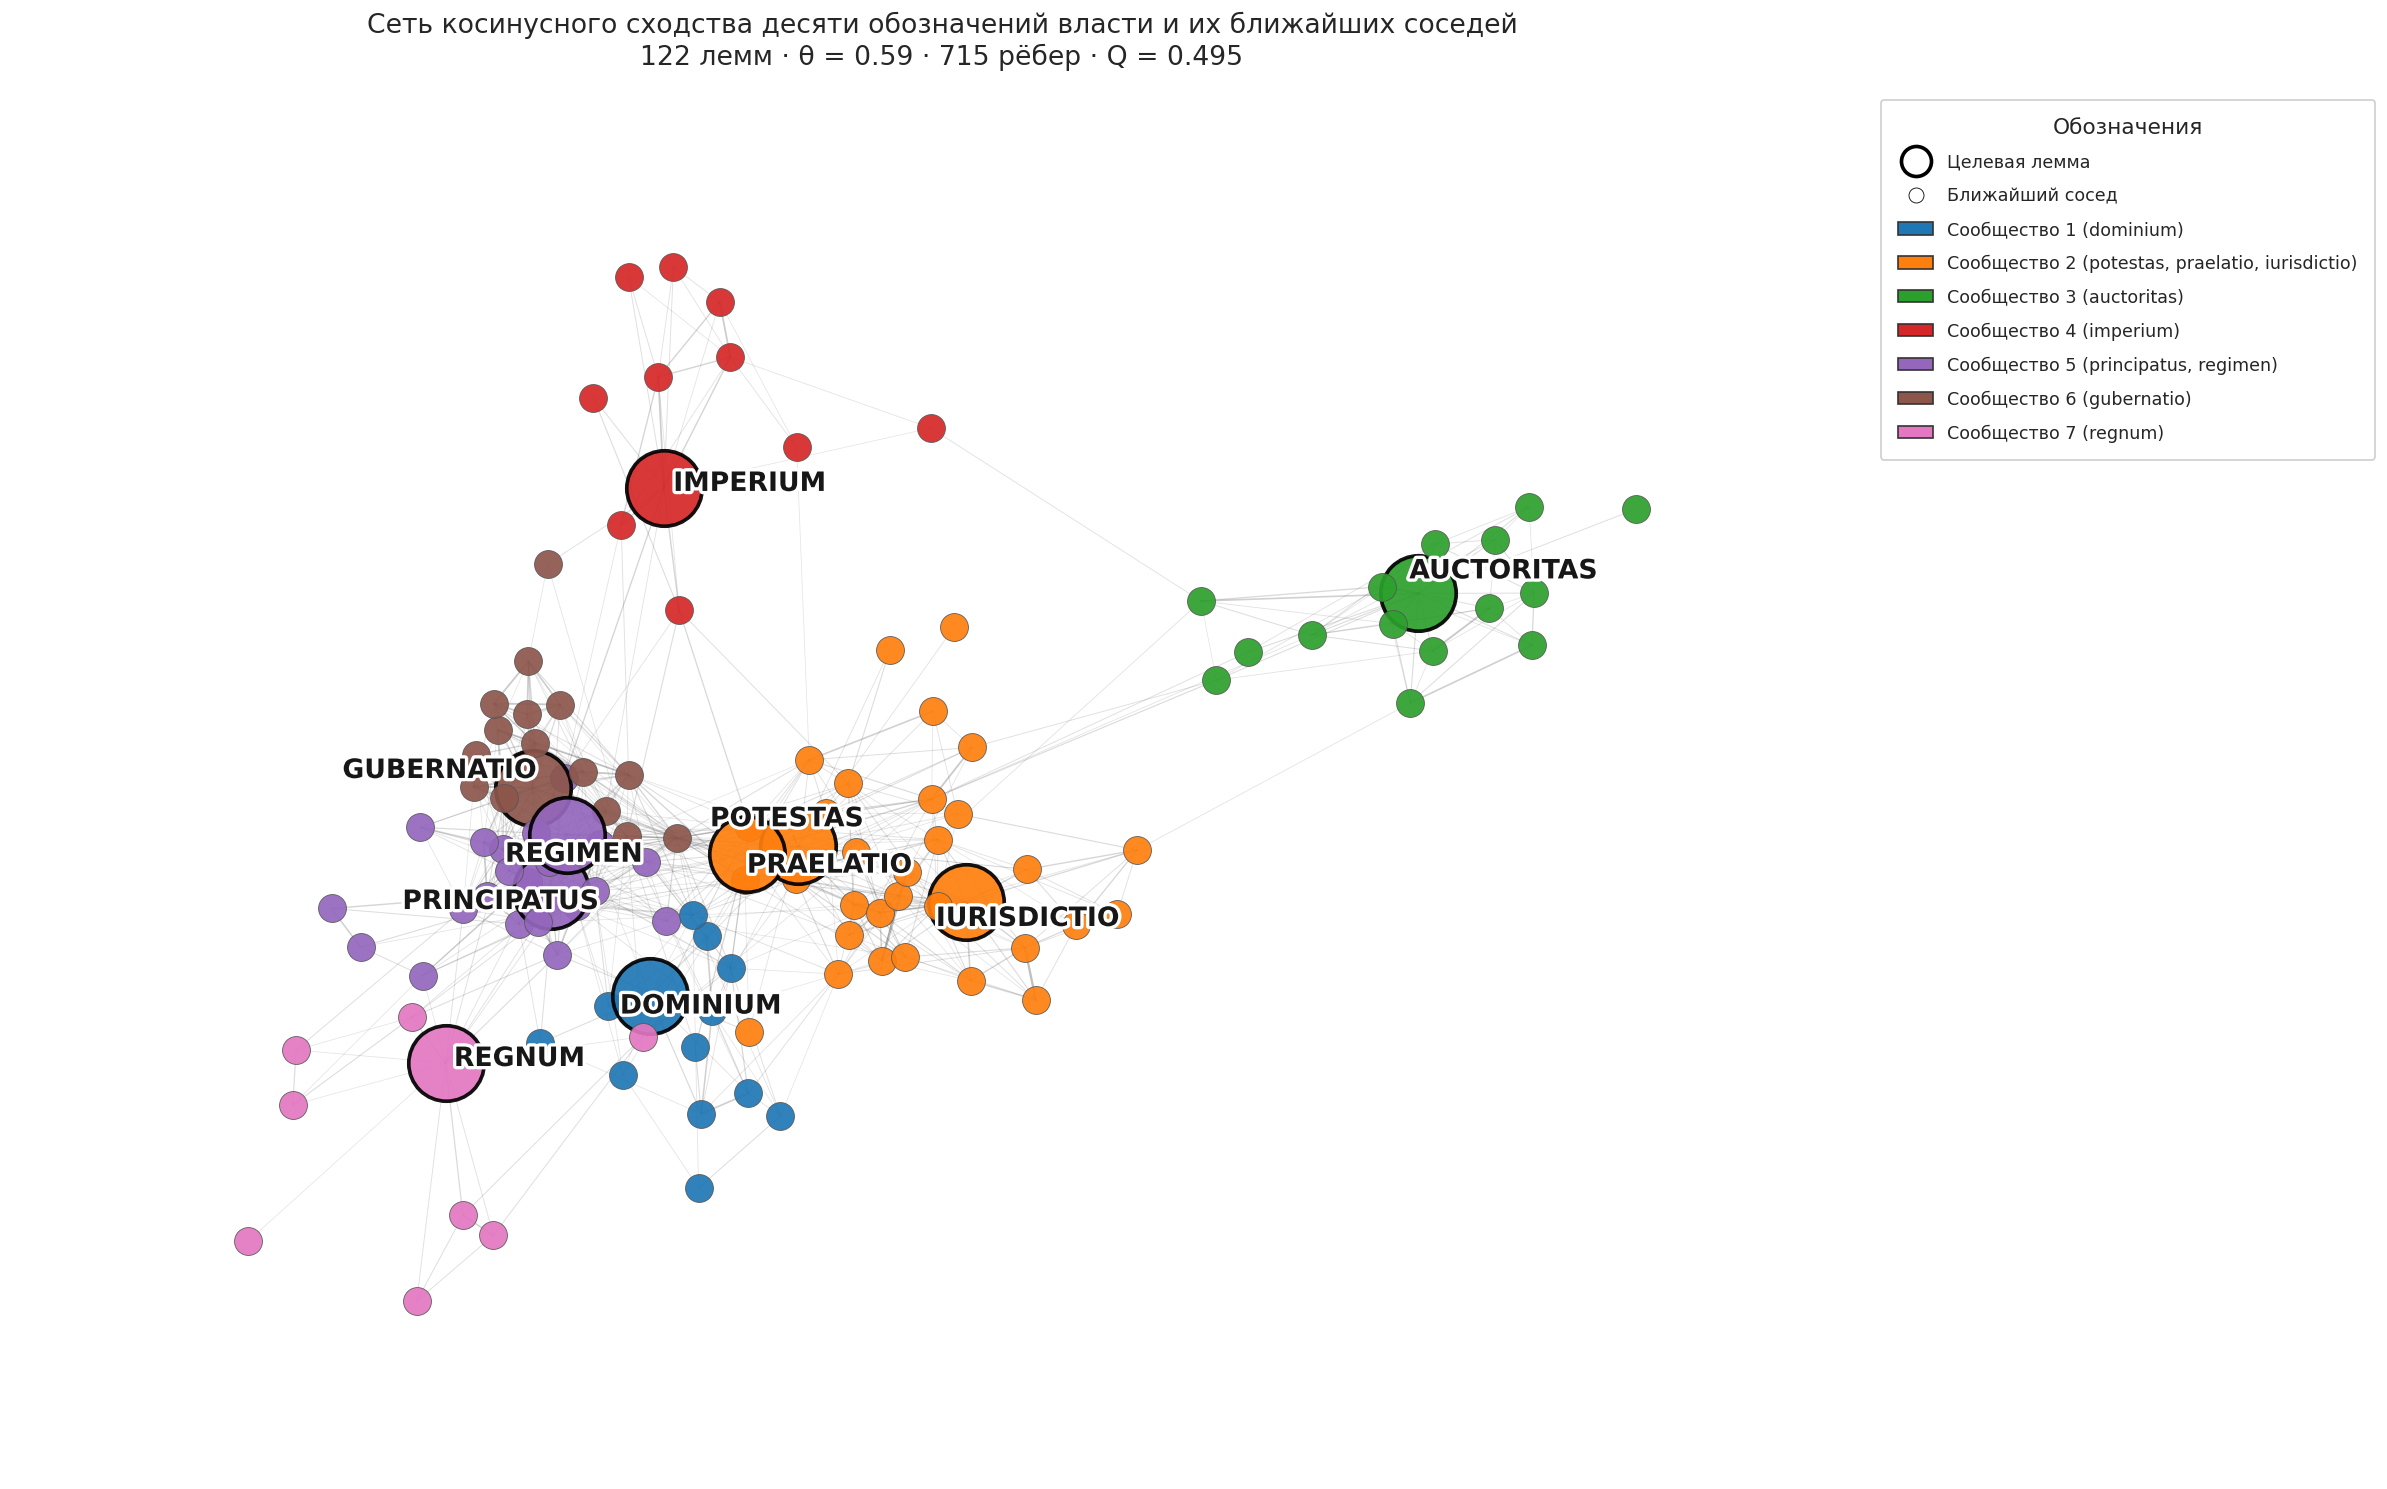

In [25]:
G = build_network(lemmas, similarity, THRESHOLD)
main = analyse_network(G)
membership, Q = main["membership"], main["Q"]
communities = sorted(set(membership.values()))

print(f"Основная сеть: {G.number_of_nodes()} лемм, {G.number_of_edges()} рёбер, θ = {THRESHOLD:.2f}")
print(f"Медоид из {N_LEIDEN_RUNS} запусков: запуск {main['medoid_seed']}, "
      f"сообществ {len(communities)}, Q = {Q:.4f}")

community_table = pd.DataFrame([
    {"Сообщество": c,
     "Целевые леммы": ", ".join(t for t in TARGET_TERMS if membership[t] == c),
     "Число лемм": sum(1 for n in G if membership[n] == c),
     "Все леммы сообщества": ", ".join(sorted(n for n in G if membership[n] == c))}
    for c in communities
]).set_index("Сообщество")
display(Markdown("**Сообщества основной сети (медоидное разбиение)**"))
display(community_table.style.set_properties(**{"text-align": "left", "white-space": "normal"}))
save_table(community_table, "communities_medoid")

fig = draw_network(G, membership,
                   "Сеть косинусного сходства десяти обозначений власти и их ближайших соседей\n"
                   f"{G.number_of_nodes()} лемм · θ = {THRESHOLD:.2f} · "
                   f"{G.number_of_edges()} рёбер · Q = {Q:.3f}")
save_figure(fig, "figure_1_network")

## 8. Графы отдельных сообществ

Для каждого сообщества медоидного разбиения сохраняется отдельный граф в `figures/communities/`. Показаны только связи внутри сообщества; размер узла растёт с числом таких связей.

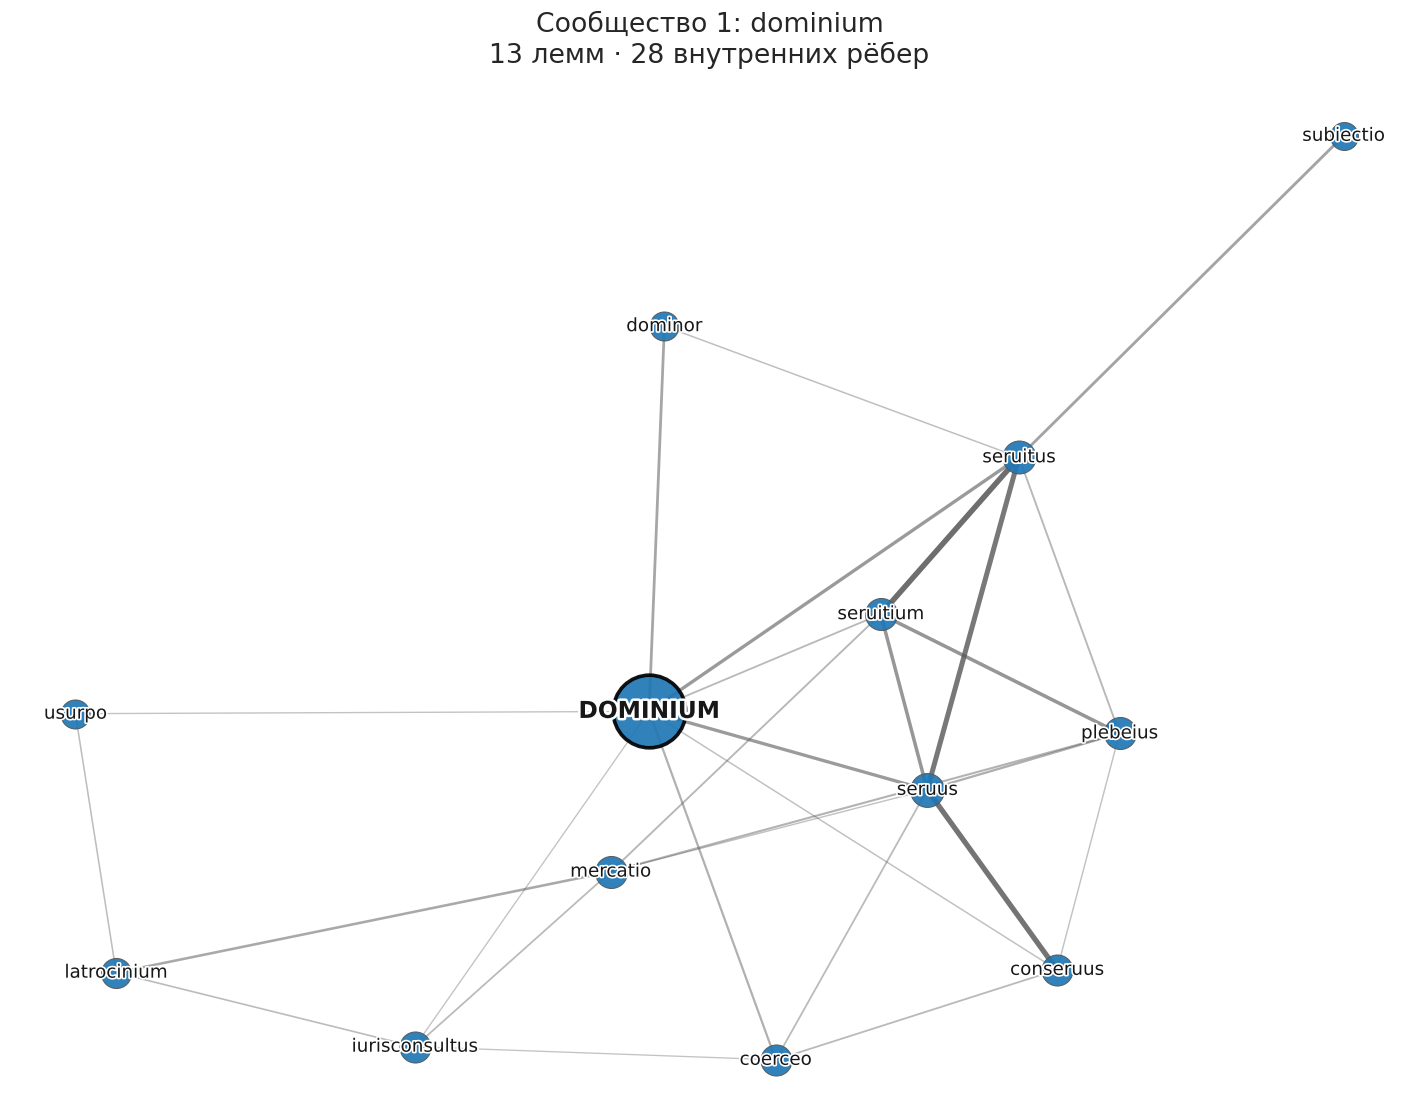

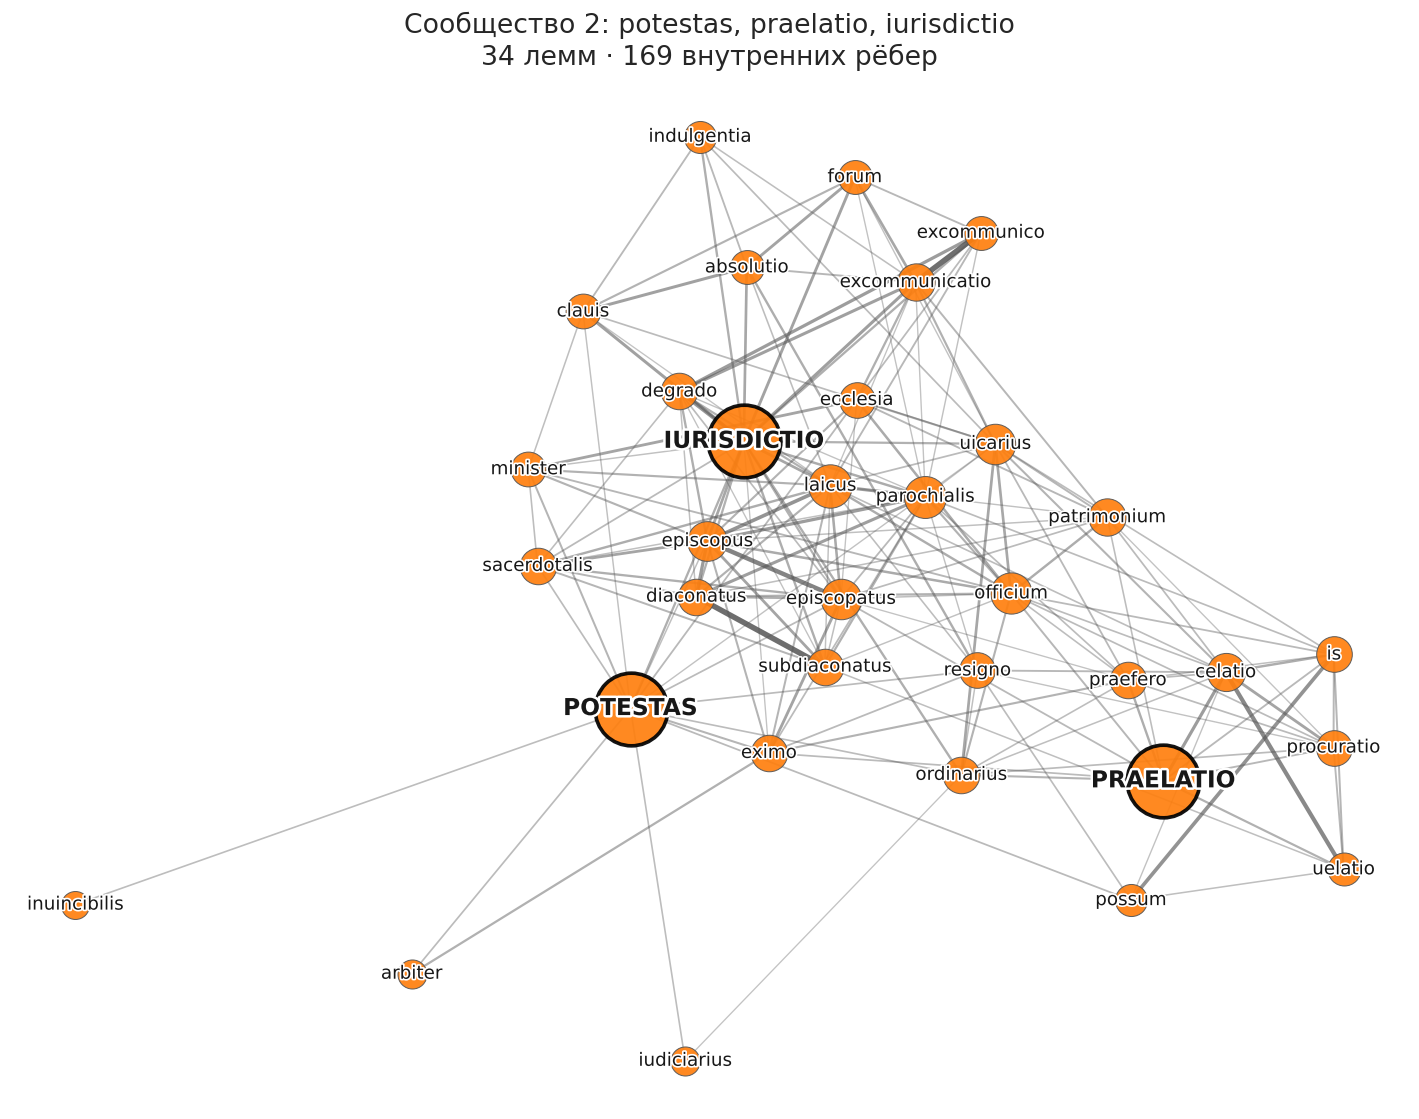

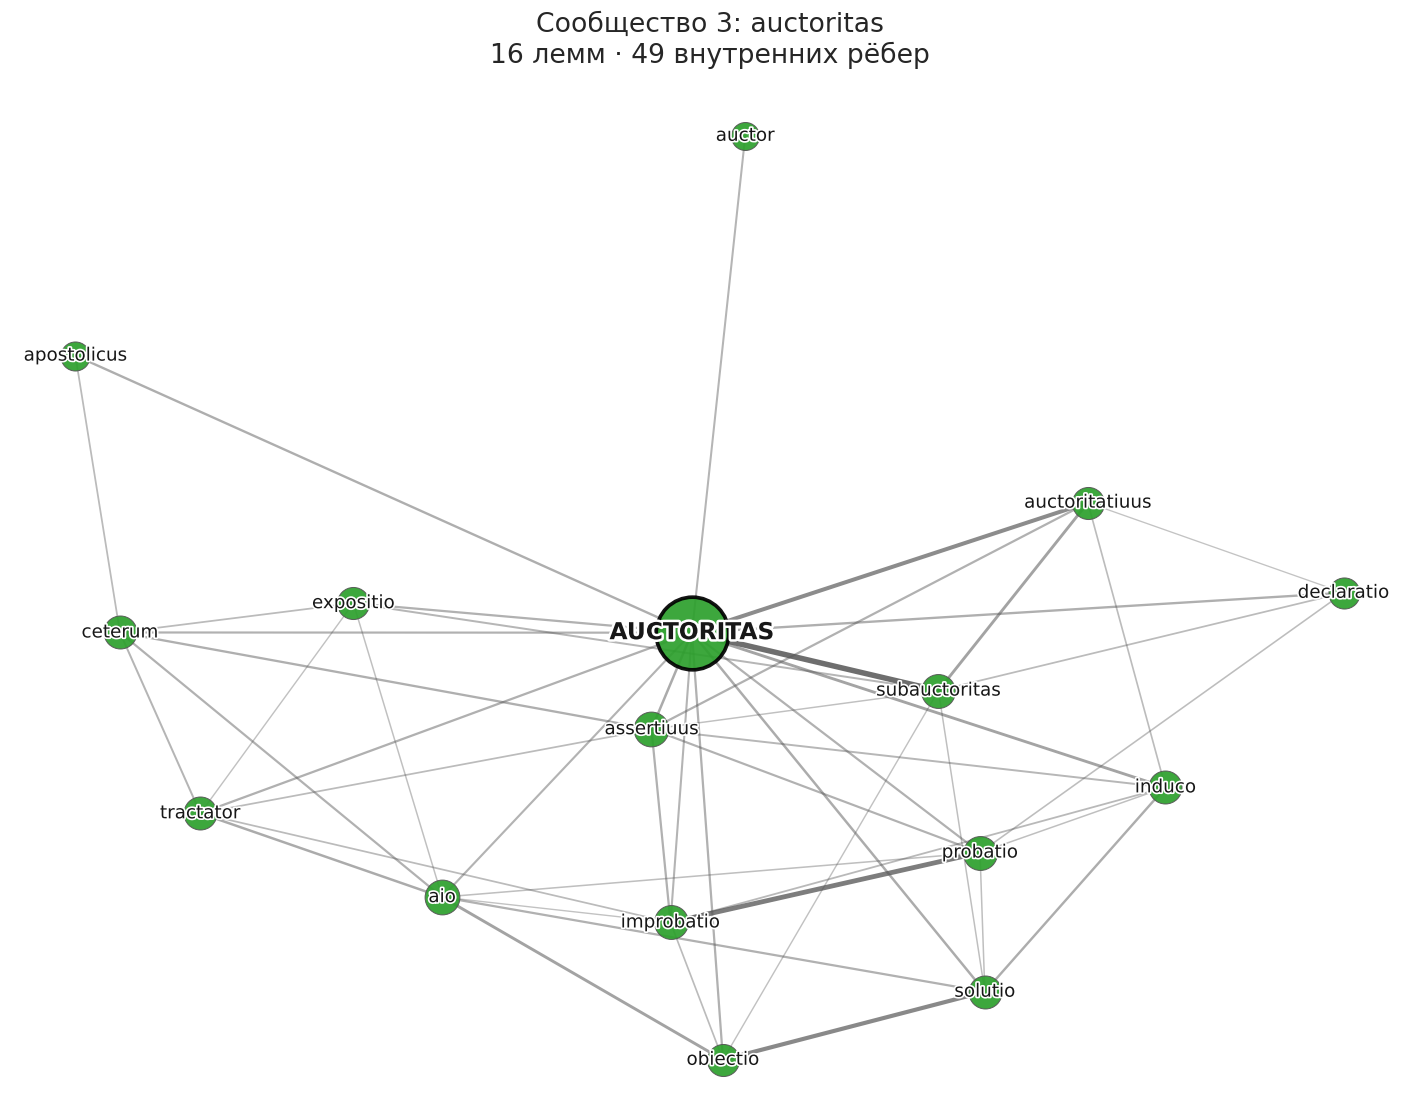

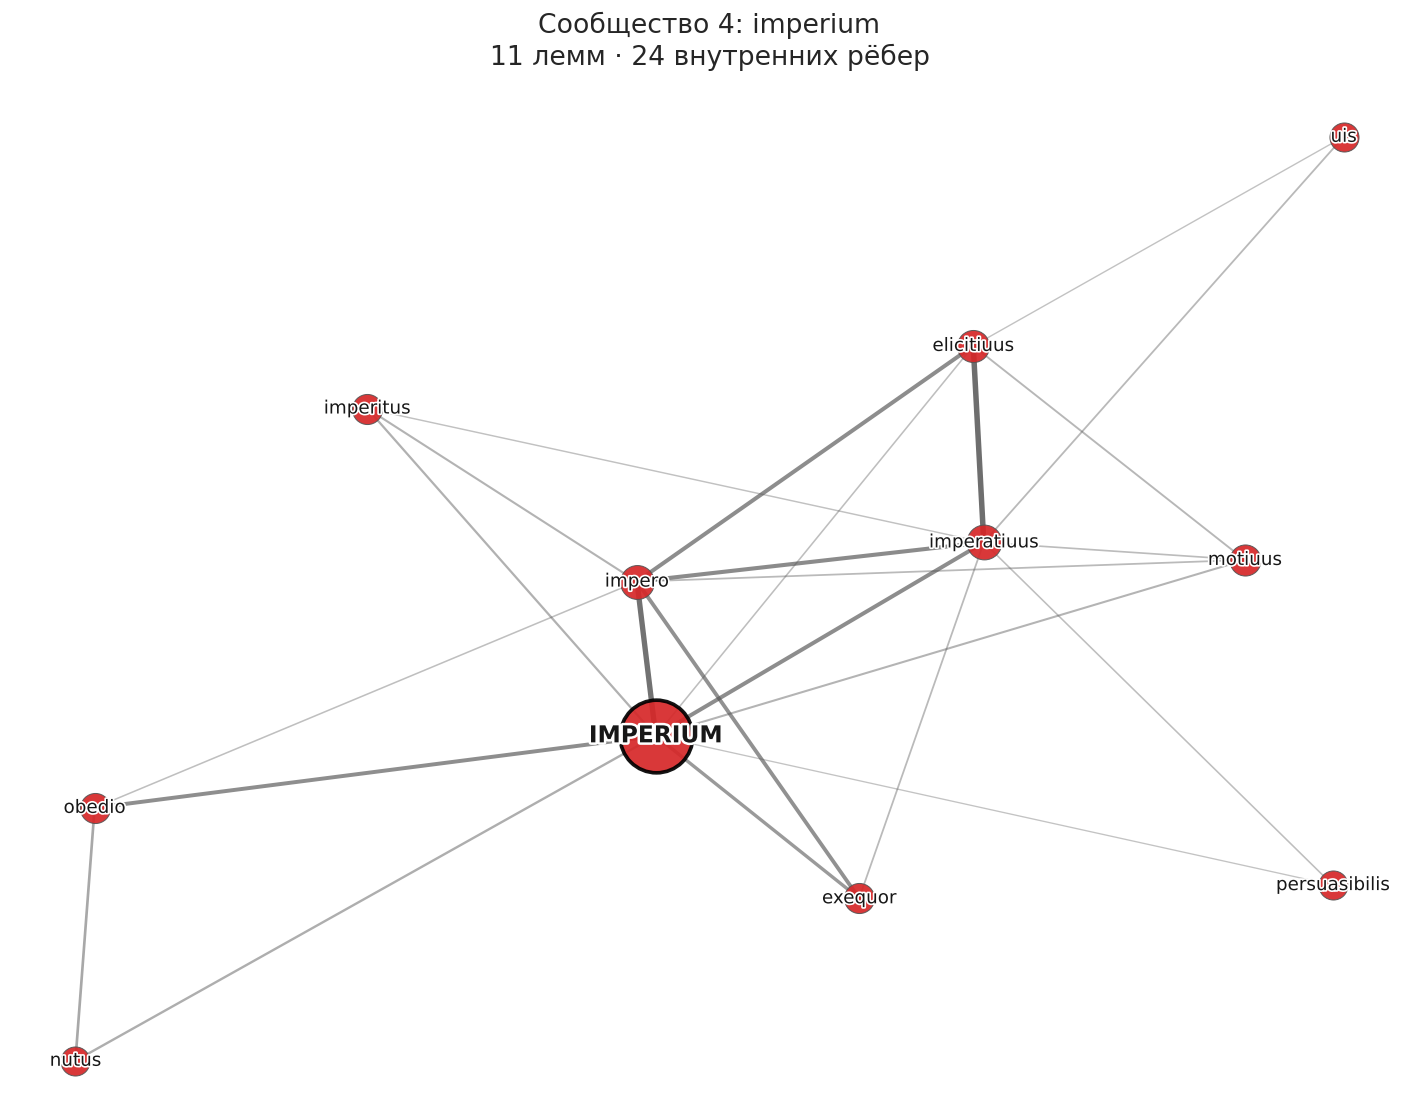

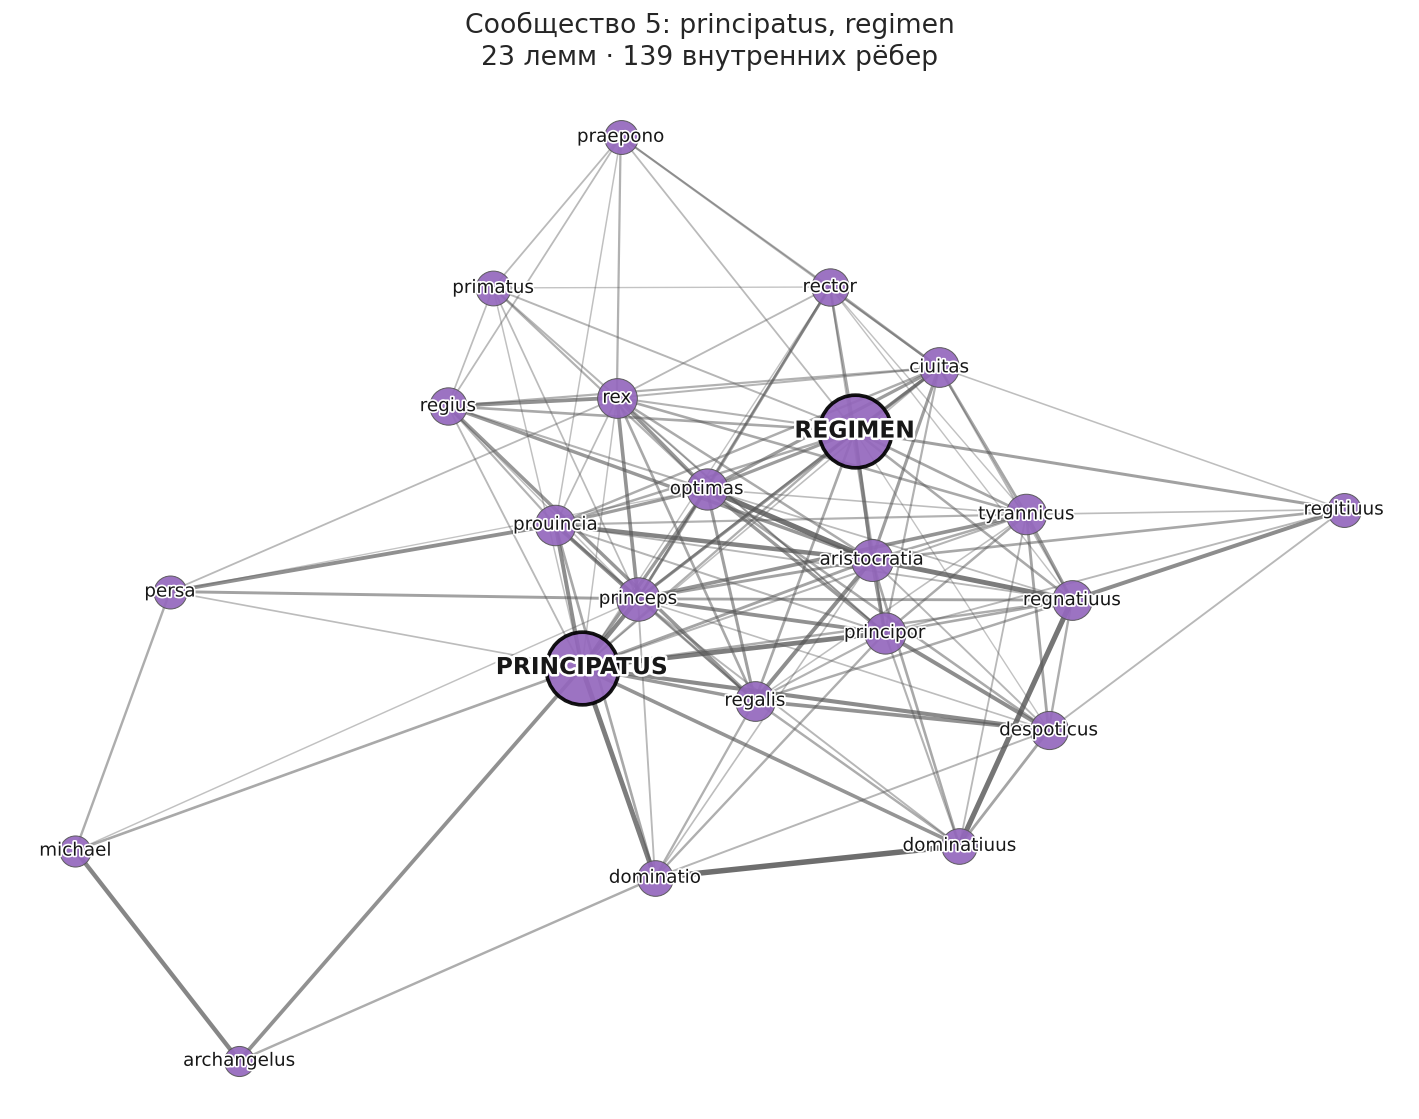

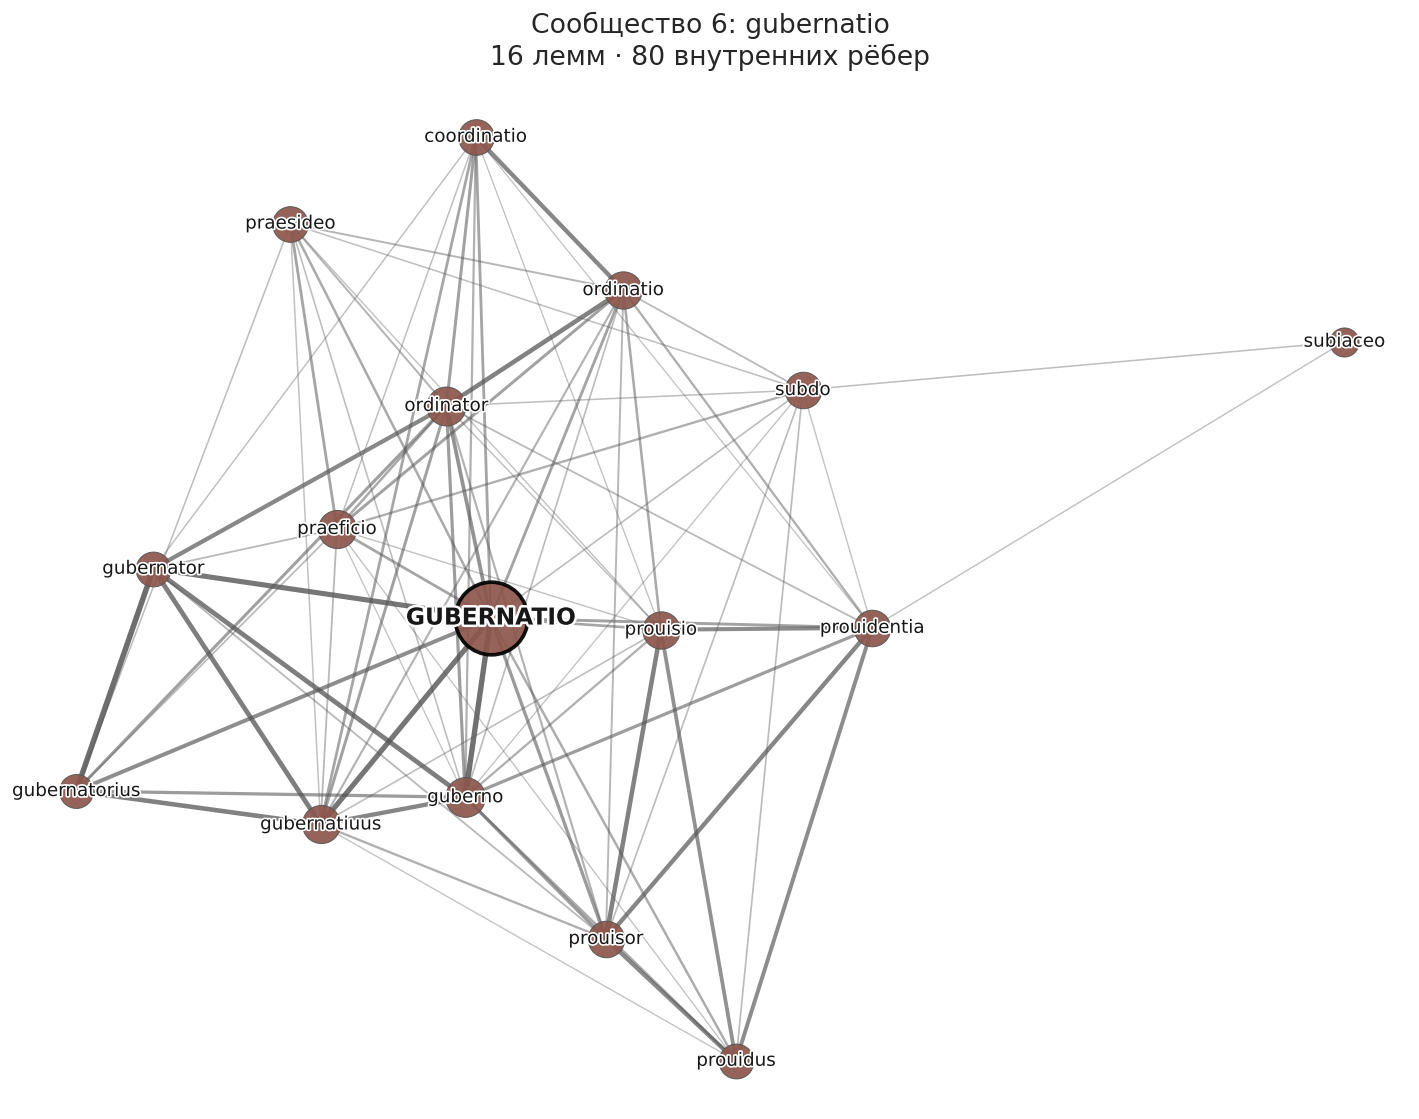

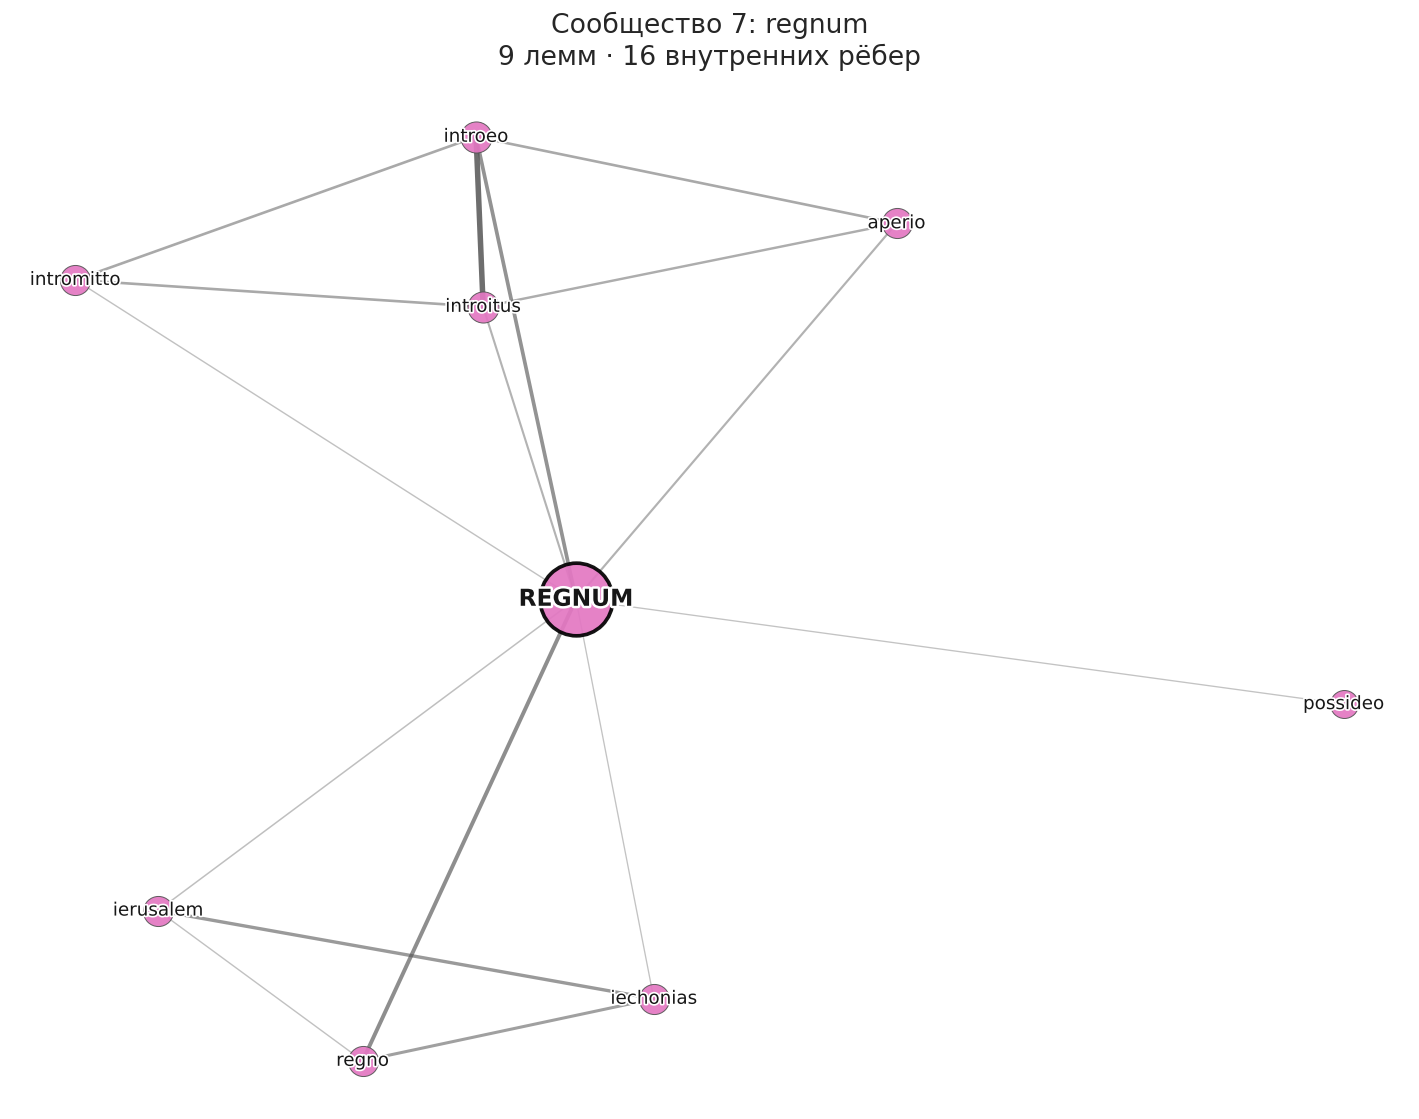

In [26]:
for c in communities:
    fig, anchor = draw_community(G, membership, c)
    save_figure(fig, f"community_{c}_{anchor}", folder=os.path.join(FIG_DIR, "communities"))

## 9. Локальные сети по схеме 6–4

Для каждой целевой леммы строится локальная сеть: шесть ближайших соседей леммы и по четыре ближайших соседа каждого из них. Порог здесь не применяется, рёбра заданы самим отбором соседей. Локальные сети служат описанию ближайшего окружения слова и не меняют словарь основной сети. Рисунки сохраняются в `figures/local_networks/`.

**Локальные сети десяти целевых лемм**

,Шесть соседей первого уровня,Другие целевые леммы (уровень),Узлов,Рёбер
Лемма,,,,
dominium,"seruitus, seruus, dominor, coerceo, potestas, ...","potestas (1-й), iurisdictio (2-й)",24,28
potestas,"iurisdictio, eximo, minister, dominium, eccles...","dominium (1-й), iurisdictio (1-й)",30,30
praelatio,"celatio, subiectio, praefero, uelatio, plebeiu...",–,28,29
iurisdictio,"degrado, excommunicatio, clauis, forum, episco...",–,22,28
auctoritas,"subauctoritas, auctoritatiuus, induco, asserti...",–,29,30
imperium,"impero, imperatiuus, obedio, despoticus, exequ...",principatus (2-й),24,28
principatus,"dominatio, principor, princeps, despoticus, pr...",imperium (2-й),22,27
regimen,"praeficio, gubernatiuus, gubernatio, aristocra...",gubernatio (1-й),22,28
gubernatio,"guberno, gubernatiuus, gubernator, gubernatori...",–,14,23


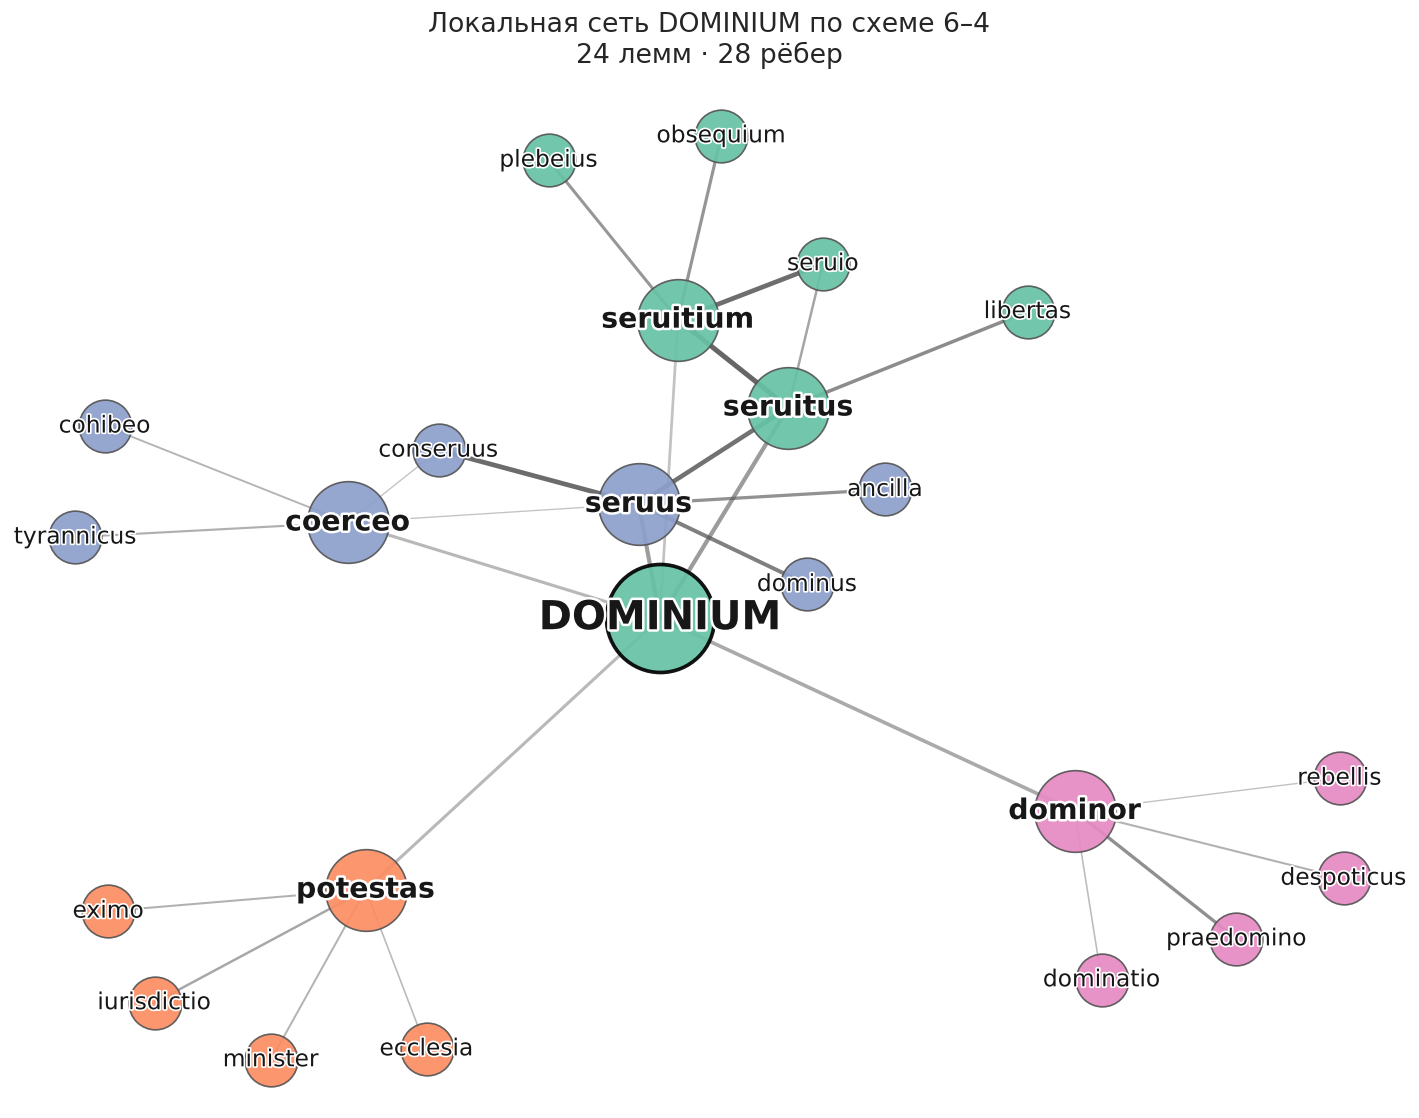

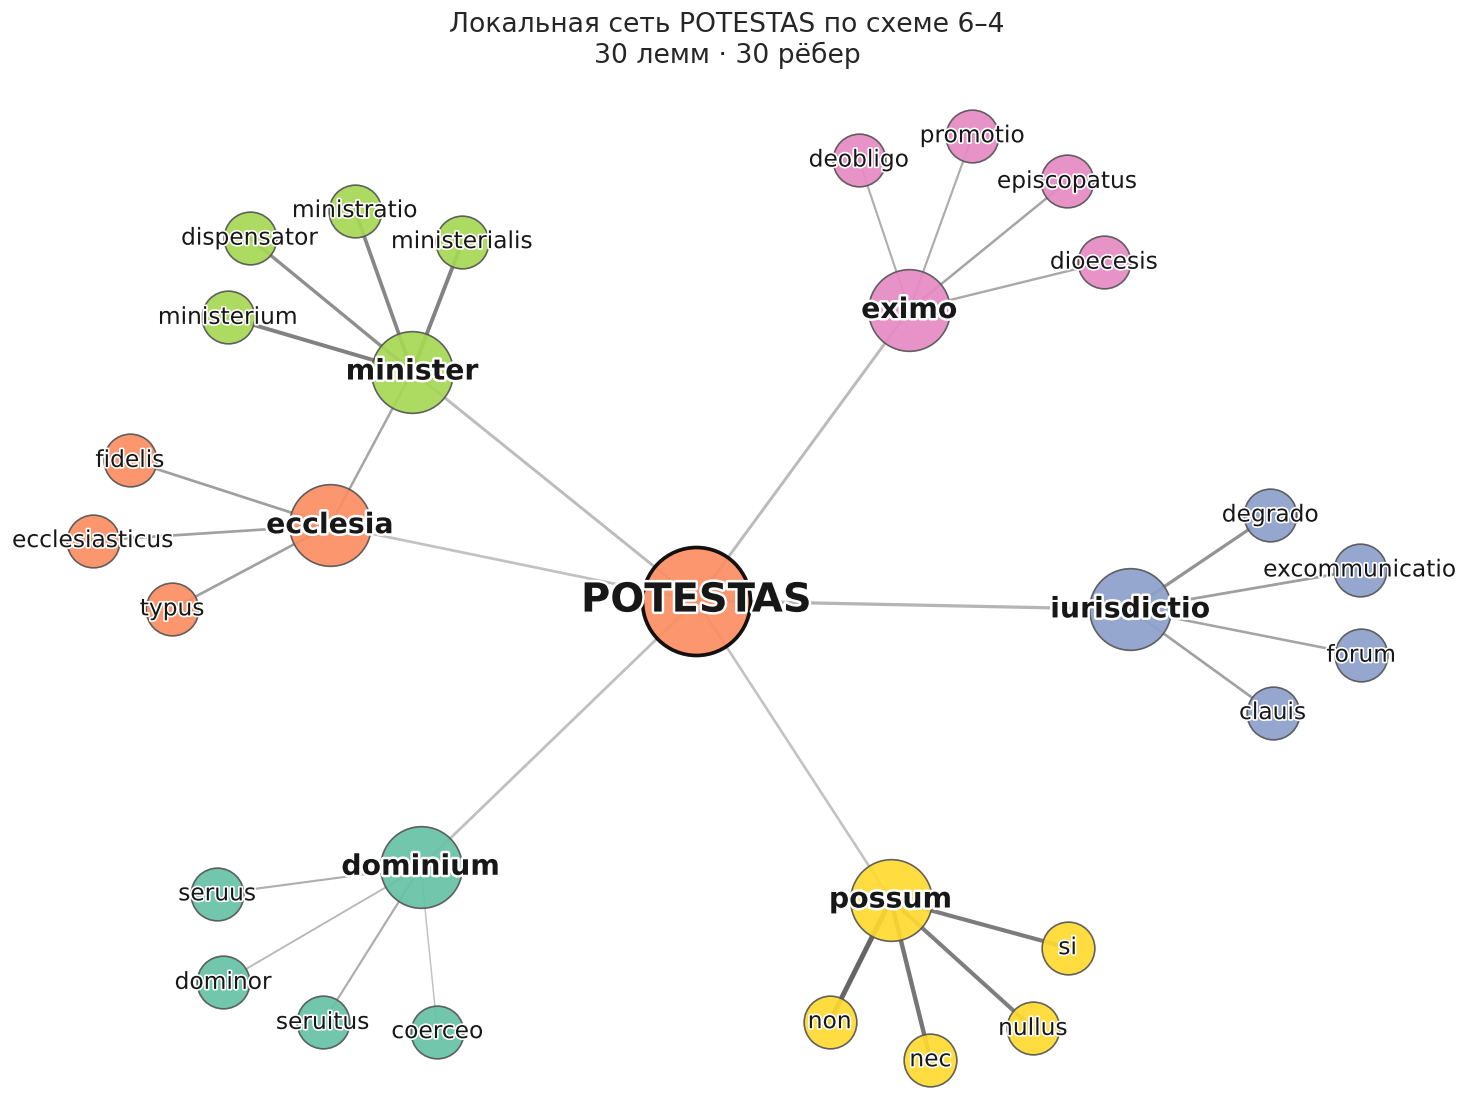

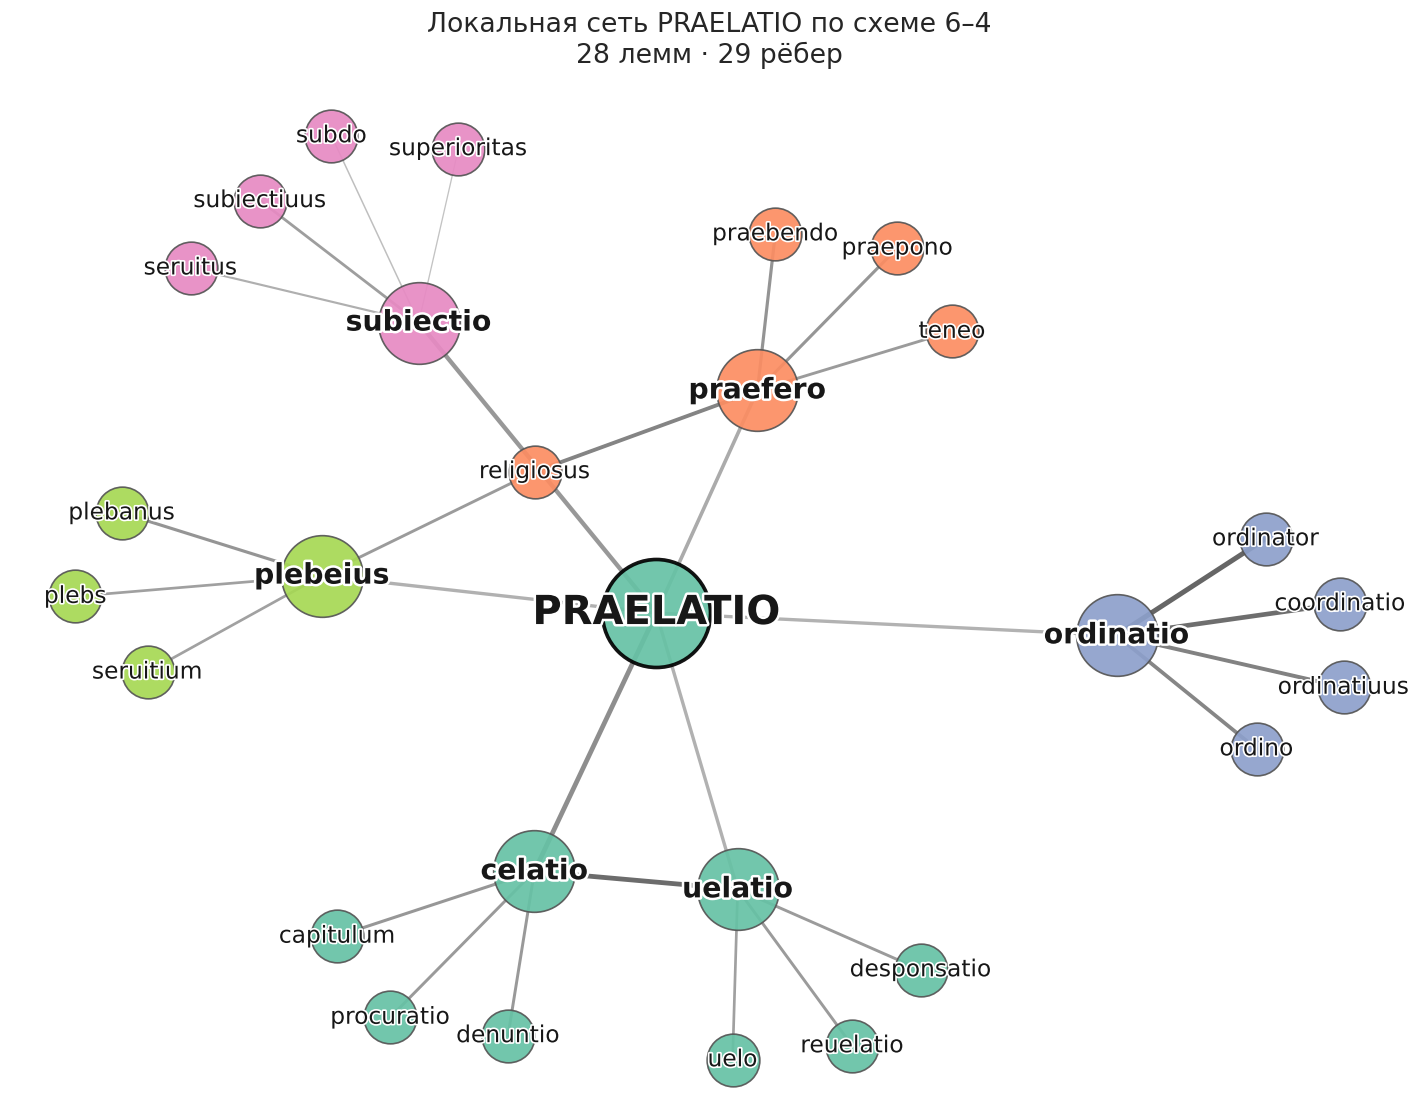

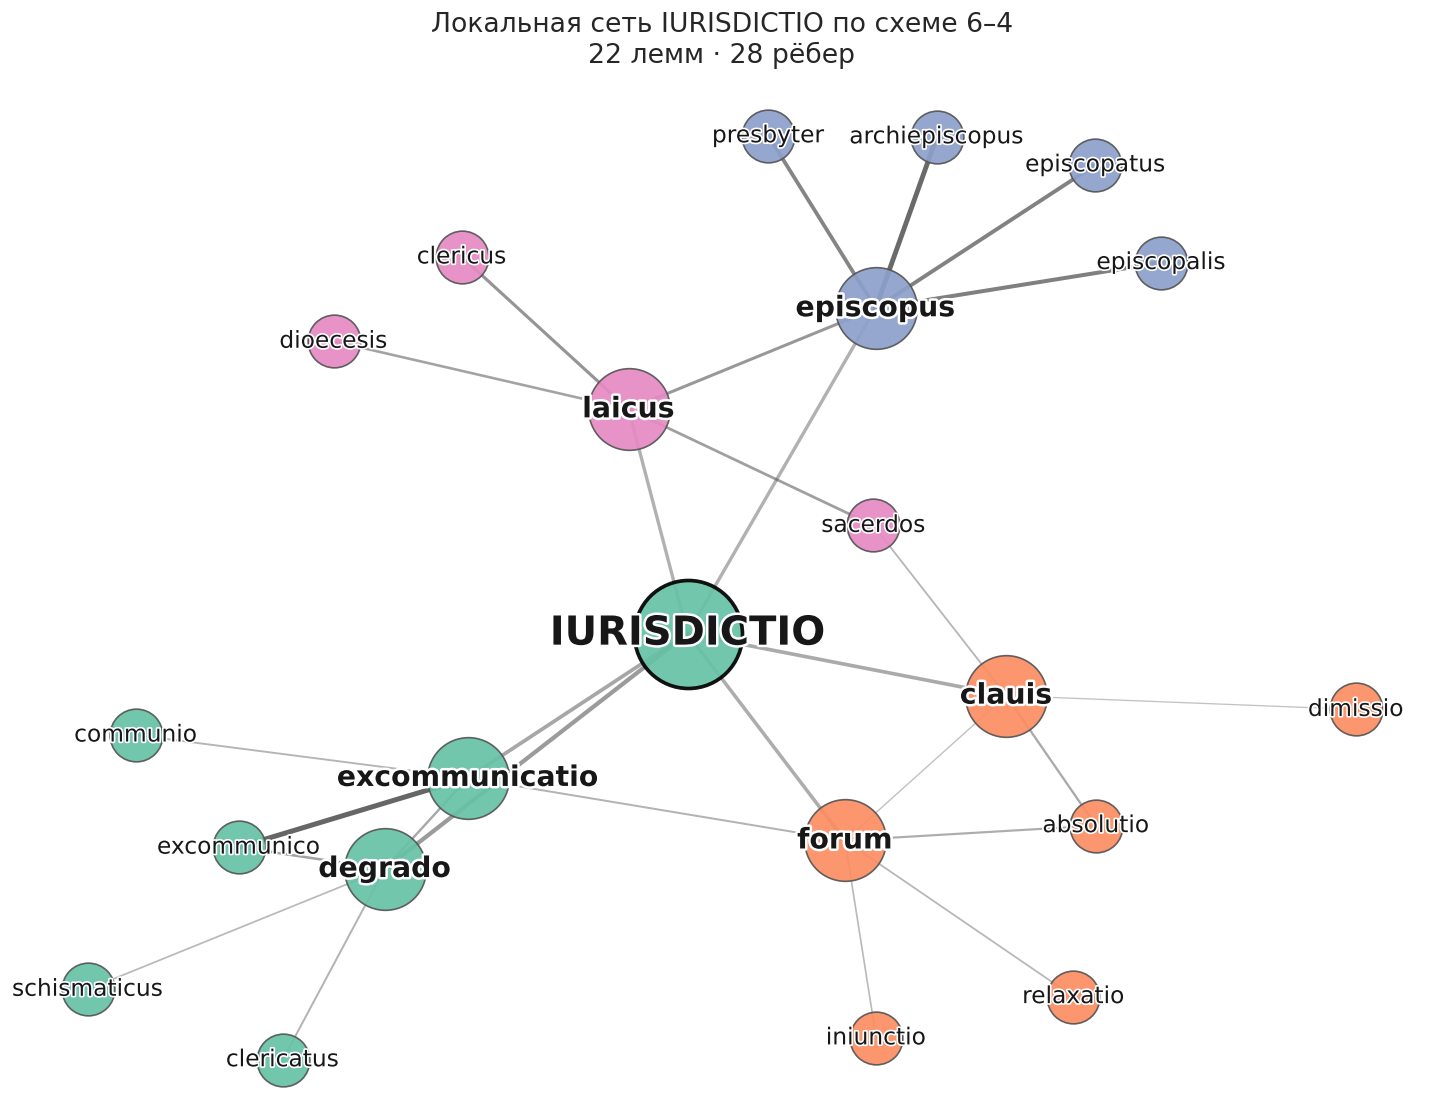

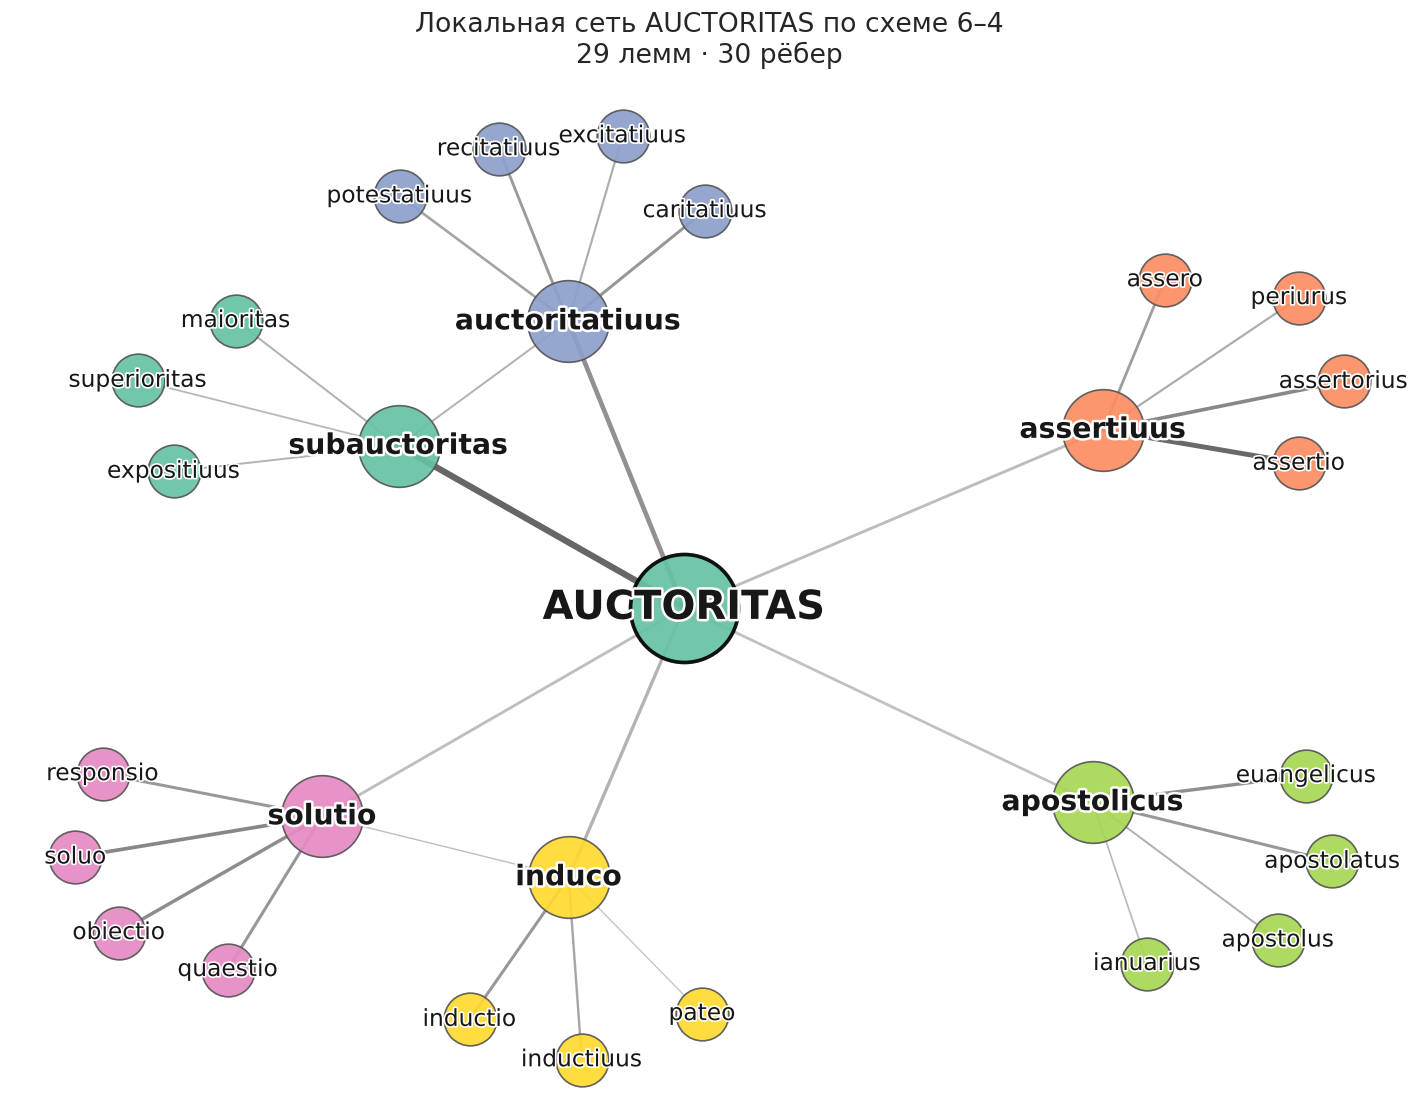

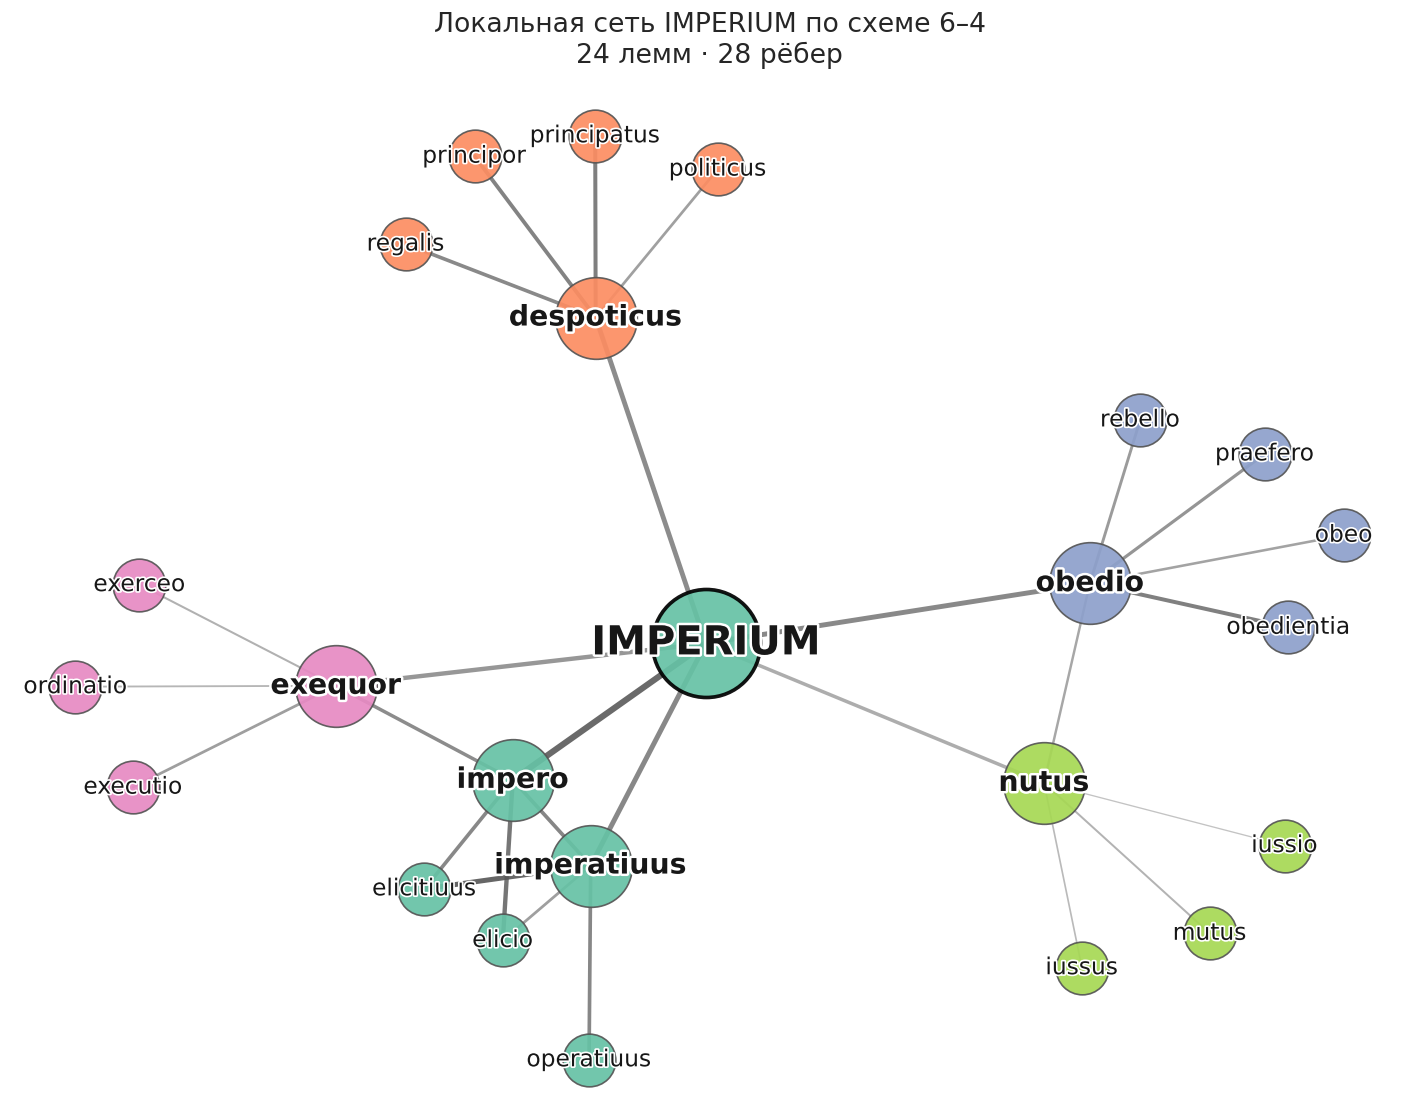

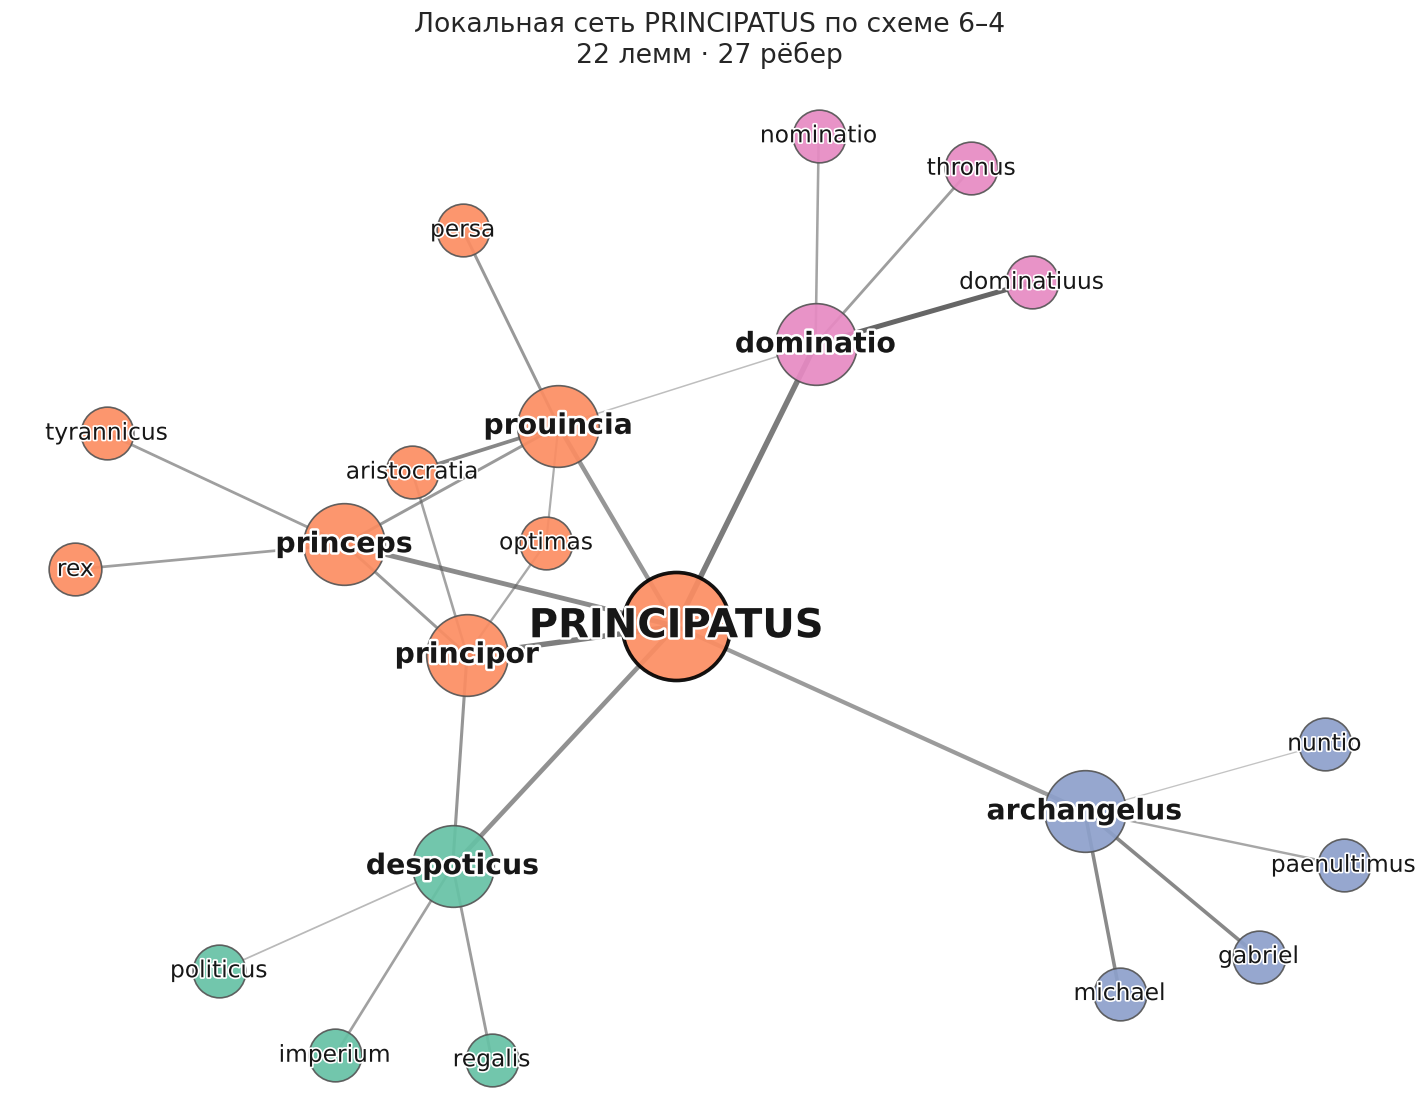

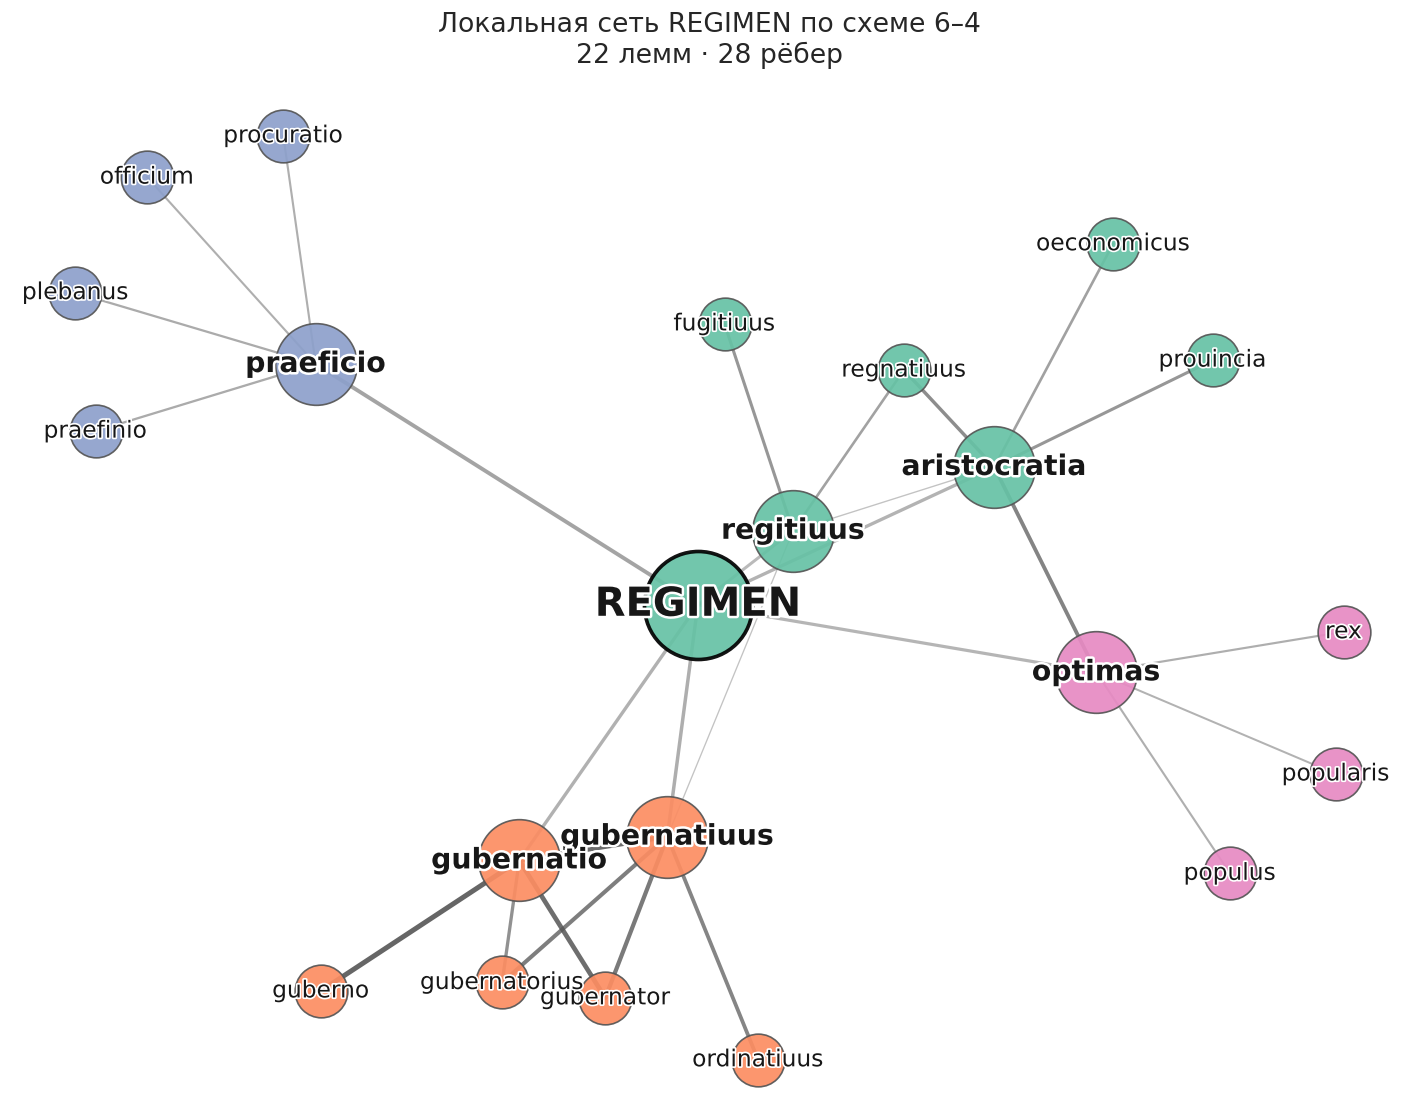

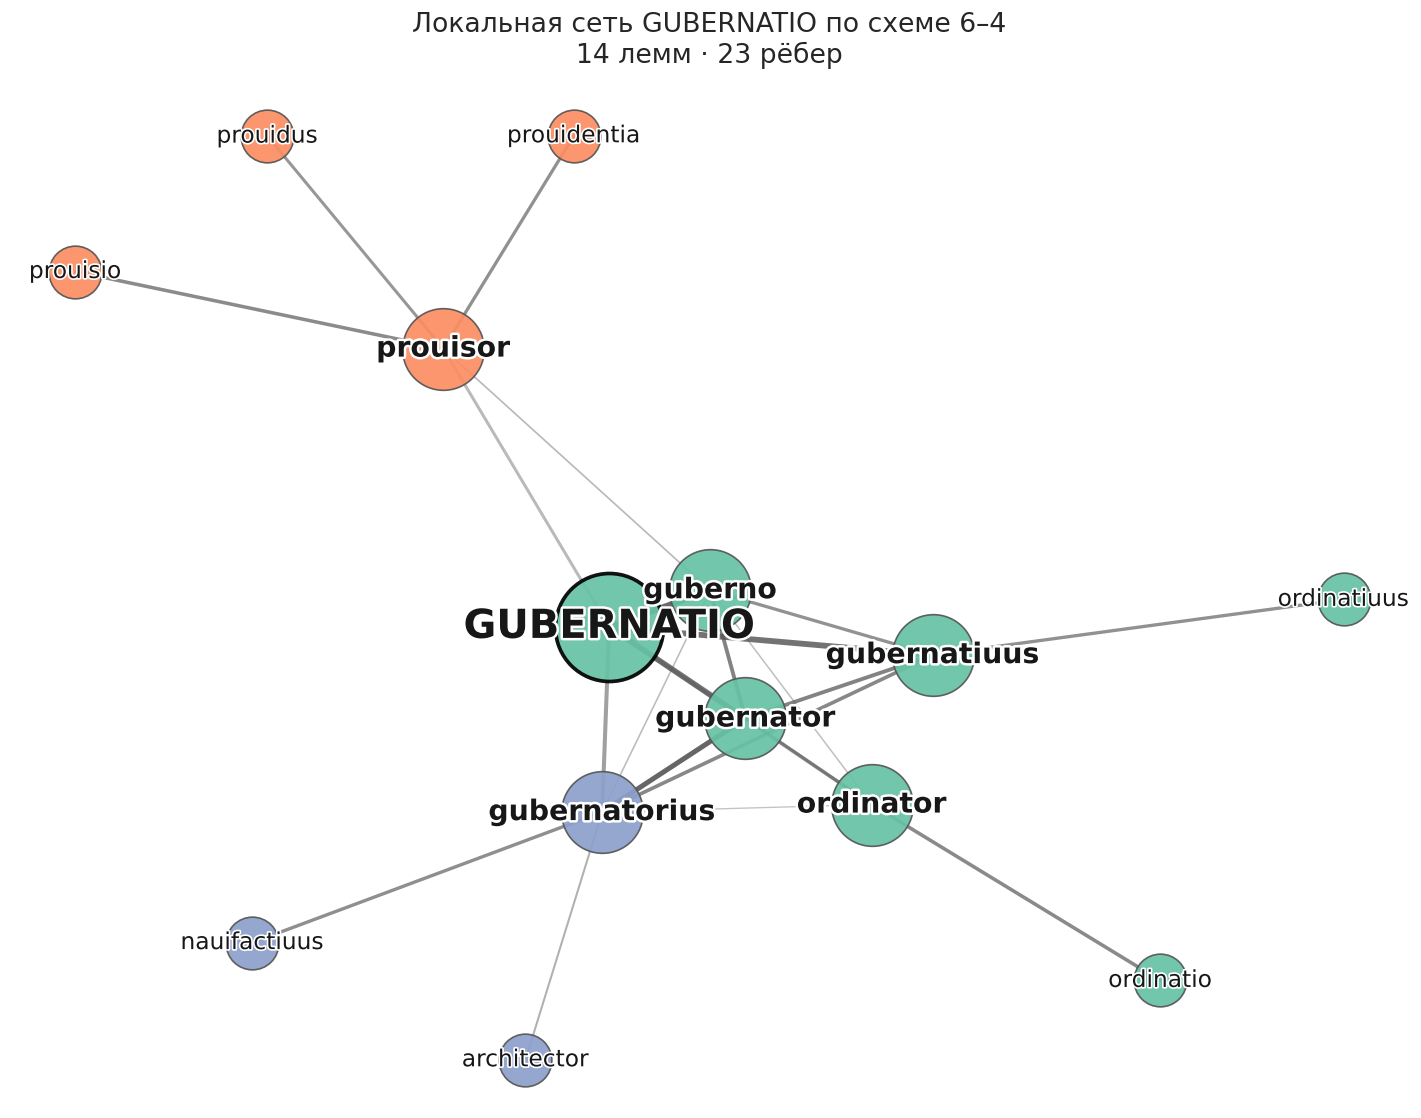

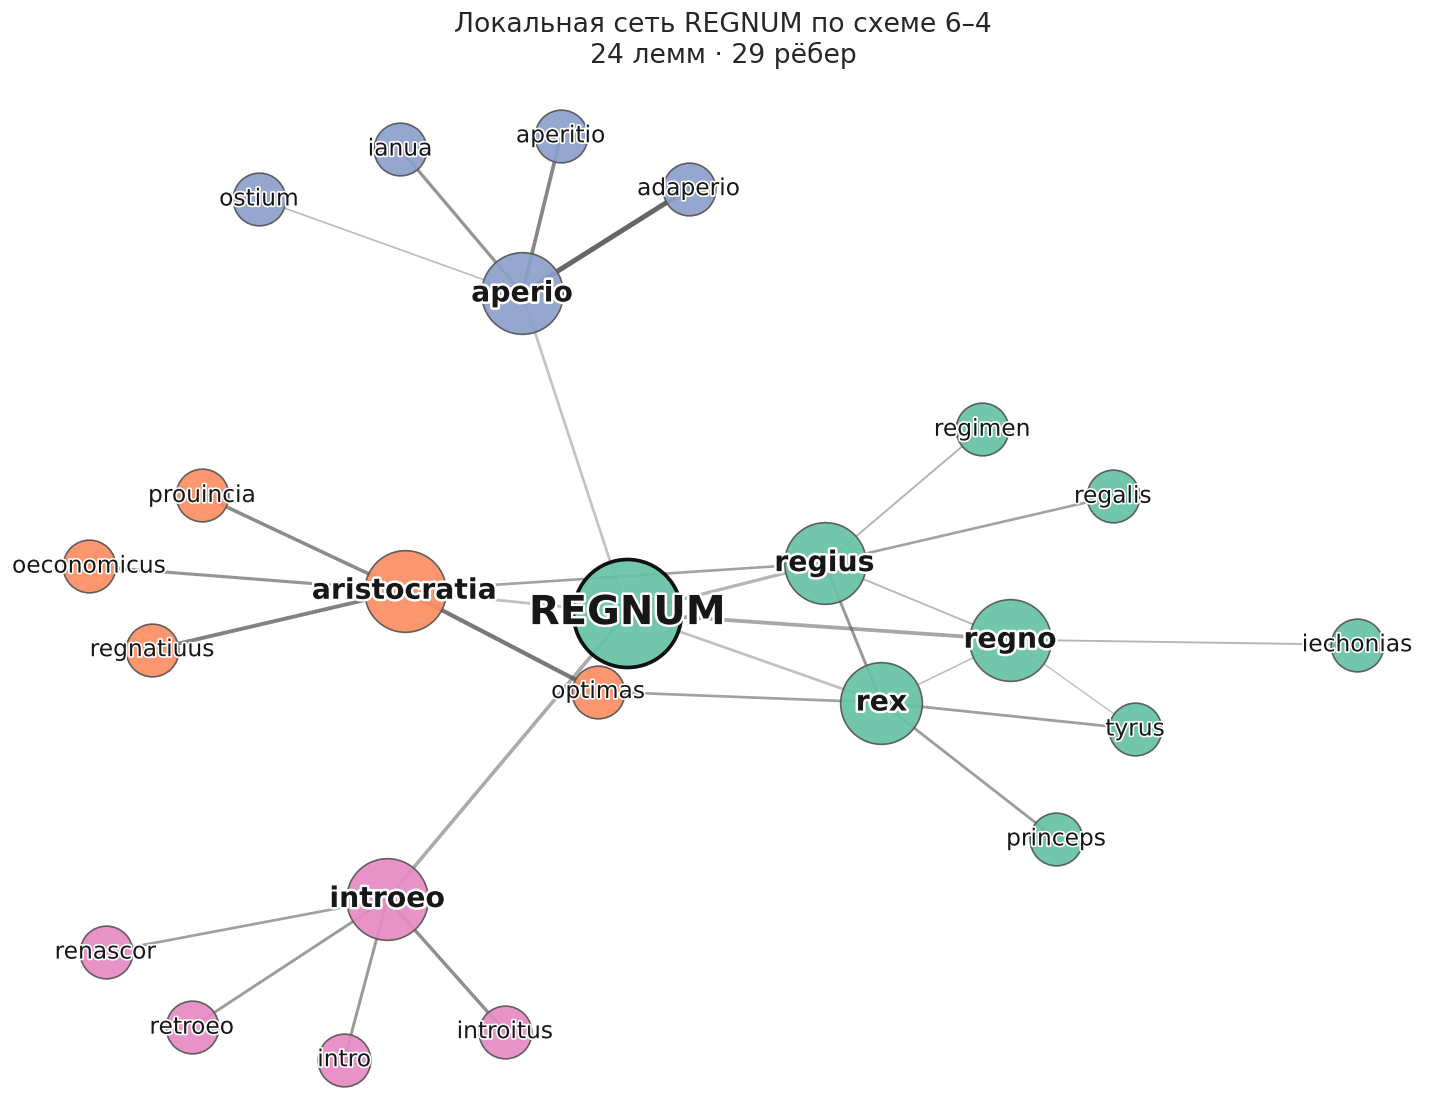

In [27]:
local_networks = {term: local_network_6_4(term) for term in TARGET_TERMS}

local_table = pd.DataFrame([
    {"Лемма": term,
     "Шесть соседей первого уровня": ", ".join(w for w, _ in wv.most_similar(term, topn=LOCAL_FIRST)),
     "Другие целевые леммы (уровень)": ", ".join(
         f"{t} ({g.nodes[t]['level']}-й)" for t in TARGET_TERMS if t in g and t != term) or "–",
     "Узлов": g.number_of_nodes(), "Рёбер": g.number_of_edges()}
    for term, g in local_networks.items()
]).set_index("Лемма")
display(Markdown("**Локальные сети десяти целевых лемм**"))
display(local_table)
save_table(local_table, "local_networks")

for term, g in local_networks.items():
    save_figure(draw_local_network(term, g), f"local_6_4_{term}",
                folder=os.path.join(FIG_DIR, "local_networks"))

## 10. Матрица косинусного сходства целевых лемм

Тепловая карта показывает прямое косинусное сходство каждой пары целевых лемм. Строки и столбцы упорядочены по сообществам медоидного разбиения, чёрные линии разделяют сообщества. Само сходство от разбиения не зависит.

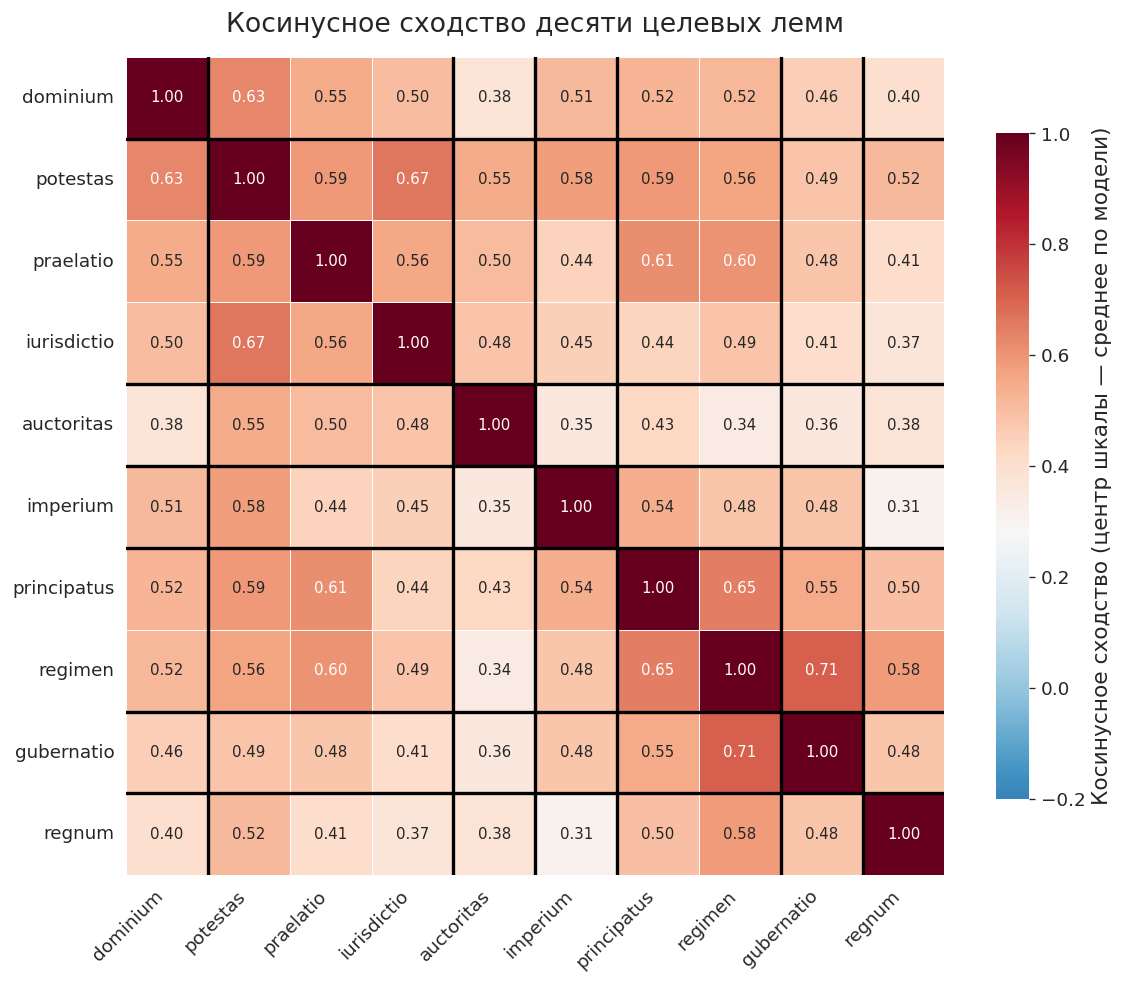

In [28]:
order = sorted(TARGET_TERMS, key=lambda t: (membership[t], TARGET_TERMS.index(t)))
boundaries = [i for i in range(1, len(order)) if membership[order[i]] != membership[order[i - 1]]]
idx = [lemmas.index(t) for t in order]
matrix = pd.DataFrame(similarity[np.ix_(idx, idx)], index=order, columns=order)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(matrix, cmap="RdBu_r", center=mean_sim, vmin=-0.2, vmax=1.0, annot=True, fmt=".2f",
            annot_kws={"size": 9}, linewidths=0.5, linecolor="white", square=True,
            cbar_kws={"label": "Косинусное сходство (центр шкалы — среднее по модели)", "shrink": 0.8}, ax=ax)
for boundary in boundaries:
    ax.axhline(boundary, color="black", linewidth=2)
    ax.axvline(boundary, color="black", linewidth=2)
ax.set_title("Косинусное сходство десяти целевых лемм", pad=15)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
save_figure(fig, "figure_2_similarity_matrix")

## 11. Попарное сходство и положение целевых лемм в сети

Для всех 45 пар целевых лемм приводятся косинусное сходство, его отклонение от среднего по модели в стандартных отклонениях (*z*), взаимные ранги соседства и принадлежность к одному сообществу медоидного разбиения. Сходство и ранги задаются моделью, совместная принадлежность — построенной сетью.

In [29]:
def pair_row(a, b):
    c = float(wv.similarity(a, b))
    return {"Пара": f"{a} – {b}", "Косинусное сходство": round(c, 3),
            "z": round((c - mean_sim) / std_sim, 1),
            "Место второй леммы среди соседей первой": int(wv.rank(a, b)),
            "Место первой леммы среди соседей второй": int(wv.rank(b, a)),
            "Одно сообщество медоида": "да" if membership[a] == membership[b] else "нет"}


pair_table = pd.DataFrame([pair_row(a, b) for a, b in TARGET_PAIRS]).set_index("Пара")
display(Markdown(f"**Среднее по модели** {mean_sim:.3f}, стандартное отклонение {std_sim:.3f}; "
                 f"порог основной сети θ = {THRESHOLD:.2f}"))
display(pair_table)
save_table(pair_table, "pairwise_similarity")

**Среднее по модели** 0.279, стандартное отклонение 0.108; порог основной сети θ = 0.59

,Косинусное сходство,z,Место второй леммы среди соседей первой,Место первой леммы среди соседей второй,Одно сообщество медоида
Пара,,,,,
dominium – potestas,0.632,3.3,5,4,нет
dominium – praelatio,0.547,2.5,35,107,нет
dominium – iurisdictio,0.500,2.0,95,174,нет
dominium – auctoritas,0.377,0.9,843,2074,нет
dominium – imperium,0.509,2.1,76,78,нет
dominium – principatus,0.524,2.3,53,95,нет
dominium – regimen,0.517,2.2,64,118,нет
dominium – gubernatio,0.456,1.6,198,264,нет
dominium – regnum,0.404,1.2,548,731,нет


## 12. Устойчивость при 10, 15 и 20 соседях

Для каждого N словарь формируется заново, а порог заново определяется по связности. Для каждой сети выполняются 50 запусков Лейдена. Показатель устойчивости — число запусков, в которых пара целевых лемм попала в одно сообщество.

,Порог θ,Узлов,Рёбер,Запусков Лейдена
N,,,,
10,0.60,90,400,50
15,0.59,122,715,50
20,0.58,157,1183,50


**Совместная принадлежность в 50 запусках**

,N = 10,N = 15,N = 20
Пара,,,
dominium – potestas,0,0,0
dominium – praelatio,18,2,8
dominium – iurisdictio,0,0,0
dominium – auctoritas,0,0,0
dominium – imperium,0,0,0
dominium – principatus,0,1,0
dominium – regimen,0,0,0
dominium – gubernatio,0,0,1
dominium – regnum,0,0,0


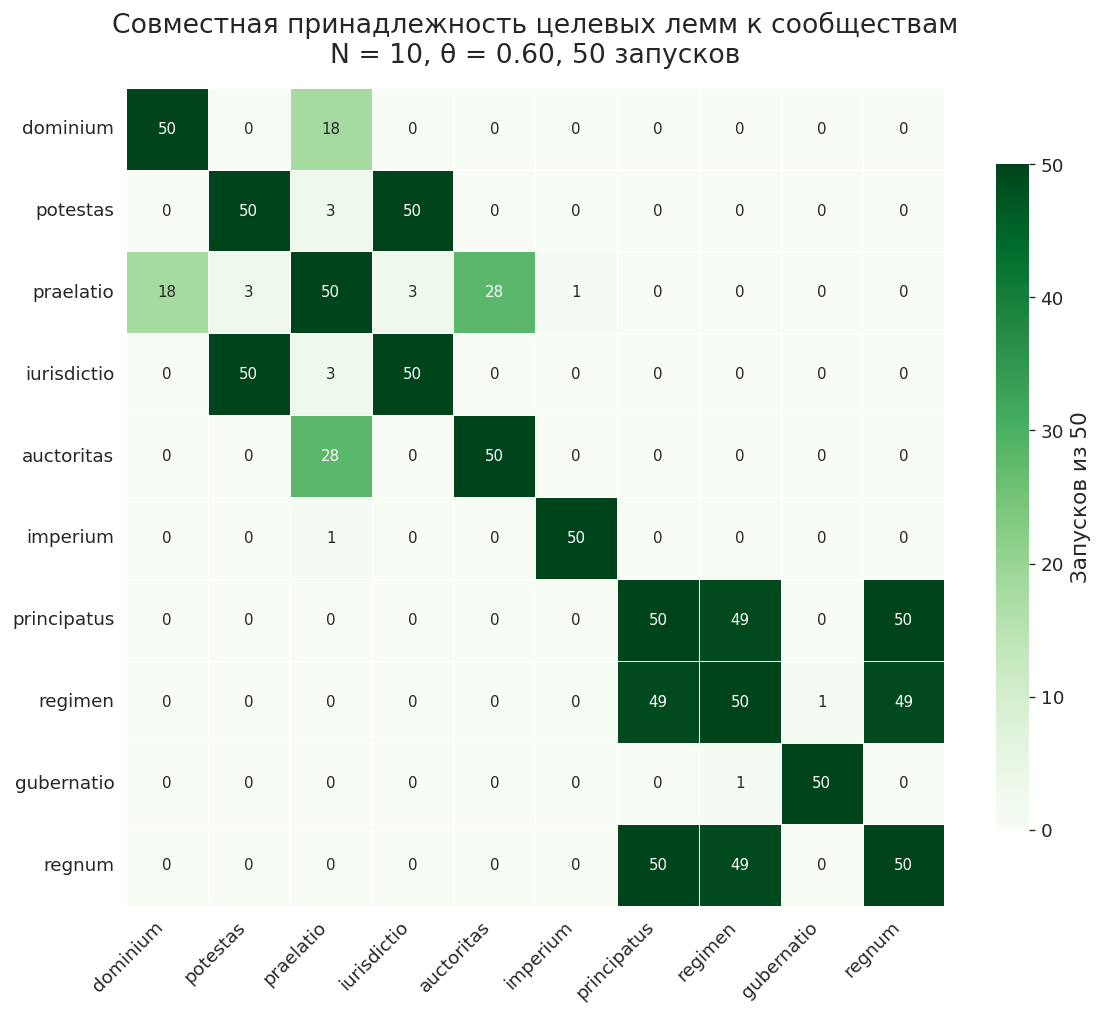

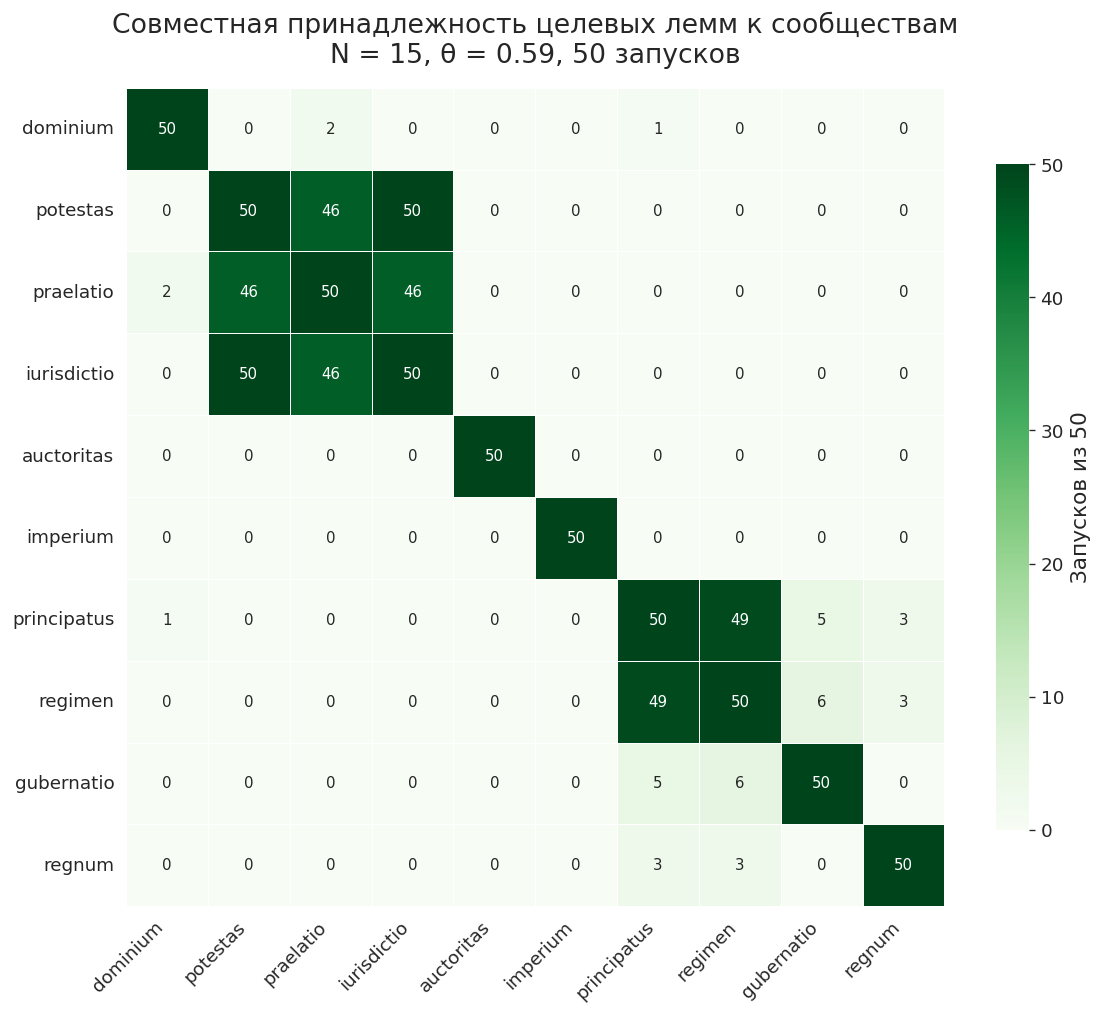

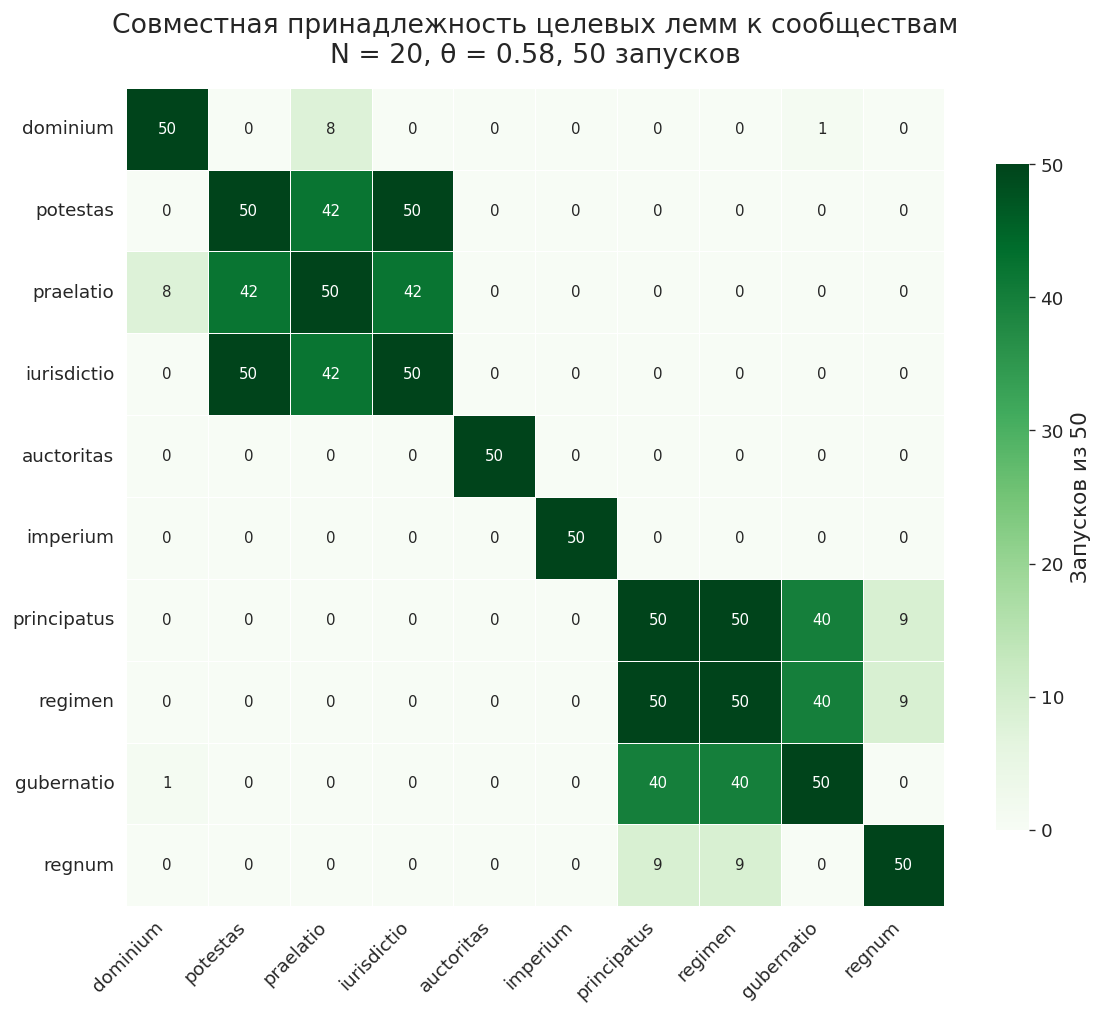

In [30]:
by_n = {TOP_N: {"lemmas": lemmas, "similarity": similarity, "threshold": THRESHOLD, **main}}
for n in TOP_N_VALUES:
    if n == TOP_N:
        continue                      # для основной сети запуски уже выполнены
    words = network_lemmas(n)
    sim = similarity_matrix(words)
    threshold = connectivity_threshold(words, sim)
    by_n[n] = {"lemmas": words, "similarity": sim, "threshold": threshold,
               **analyse_network(build_network(words, sim, threshold))}

network_summary = pd.DataFrame([
    {"N": n, "Порог θ": by_n[n]["threshold"],
     "Узлов": by_n[n]["graph"].number_of_nodes(),
     "Рёбер": by_n[n]["graph"].number_of_edges(),
     "Запусков Лейдена": N_LEIDEN_RUNS}
    for n in TOP_N_VALUES
]).set_index("N")
display(network_summary)
save_table(network_summary, "robustness_networks")

pair_counts = pd.DataFrame({
    f"N = {n}": [int(by_n[n]["together"].loc[a, b]) for a, b in TARGET_PAIRS]
    for n in TOP_N_VALUES
}, index=[f"{a} – {b}" for a, b in TARGET_PAIRS]).rename_axis("Пара")
display(Markdown(f"**Совместная принадлежность в {N_LEIDEN_RUNS} запусках**"))
display(pair_counts)
save_table(pair_counts, "robustness_pairs")

for n in TOP_N_VALUES:
    fig = draw_co_membership(by_n[n]["together"], order,
                             "Совместная принадлежность целевых лемм к сообществам\n"
                             f"N = {n}, θ = {by_n[n]['threshold']:.2f}, {N_LEIDEN_RUNS} запусков")
    save_figure(fig, f"robustness_co_membership_N{n}")

## 13. Повышение порога на 0,01

Проверяется, какие леммы отделяются от основной сети при следующем значении порога и через какие связи они были присоединены. Запуск алгоритма Лейдена здесь не нужен.

In [31]:
next_threshold = round(THRESHOLD + 0.01, 2)
parts = sorted(nx.connected_components(build_network(lemmas, similarity, next_threshold)),
               key=len, reverse=True)
detached = set().union(*parts[1:]) if len(parts) > 1 else set()

print(f"θ = {next_threshold:.2f}: компонент {len(parts)}, размеры {[len(p) for p in parts]}")
print("Отделившиеся леммы:", ", ".join(sorted(detached)) or "–")
print("Целевые леммы среди них:", ", ".join(t for t in TARGET_TERMS if t in detached) or "–")

bridges = pd.DataFrame(
    [(u, v, round(d["weight"], 3)) for u, v, d in G.edges(data=True)
     if (u in detached) != (v in detached)],
    columns=["Лемма 1", "Лемма 2", "Косинусное сходство"]
).sort_values("Косинусное сходство", ascending=False).reset_index(drop=True)
display(Markdown(f"**Связи, которые при θ = {THRESHOLD:.2f} удерживают отделившиеся леммы в сети**"))
display(bridges)
save_table(bridges, "threshold_bridges")

θ = 0.60: компонент 2, размеры [121, 1]
Отделившиеся леммы: possideo
Целевые леммы среди них: –


**Связи, которые при θ = 0.59 удерживают отделившиеся леммы в сети**

,Лемма 1,Лемма 2,Косинусное сходство
0,possideo,regnum,0.594


## 14. Дополнительные проверки

Три проверки показывают, какие группировки целевых лемм сохраняются при ином построении. Модель и словарь основной сети остаются прежними.

1. **Сеть ближайших соседей.** Вместо единого порога каждая лемма соединяется со своими восемью ближайшими соседями внутри словаря.
2. **Исключение редких лемм.** Из основной сети удаляются нецелевые леммы с частотой ниже 10; порог и веса рёбер не меняются.
3. **Иерархическая кластеризация.** Десять целевых векторов группируются напрямую, без построения сети.

Номера сообществ в разных сетях между собой не соотносятся. Сравнивать следует совместную принадлежность пар.

### 14.1. Сеть ближайших соседей (k = 8)

Используется тот же словарь, что и в основной сети. Для каждой леммы выбираются восемь ближайших соседей внутри словаря; ребро проводится, если выбор сделан хотя бы с одной стороны. Вес ребра — косинусное сходство. Значение k = 8 даёт сеть, сопоставимую по плотности с основной, и не подбиралось по модулярности или иным характеристикам сообществ.

Сеть ближайших соседей: 659 рёбер (в основной сети 715); общих рёбер 514; рёбер ниже порога θ = 0.59: 145


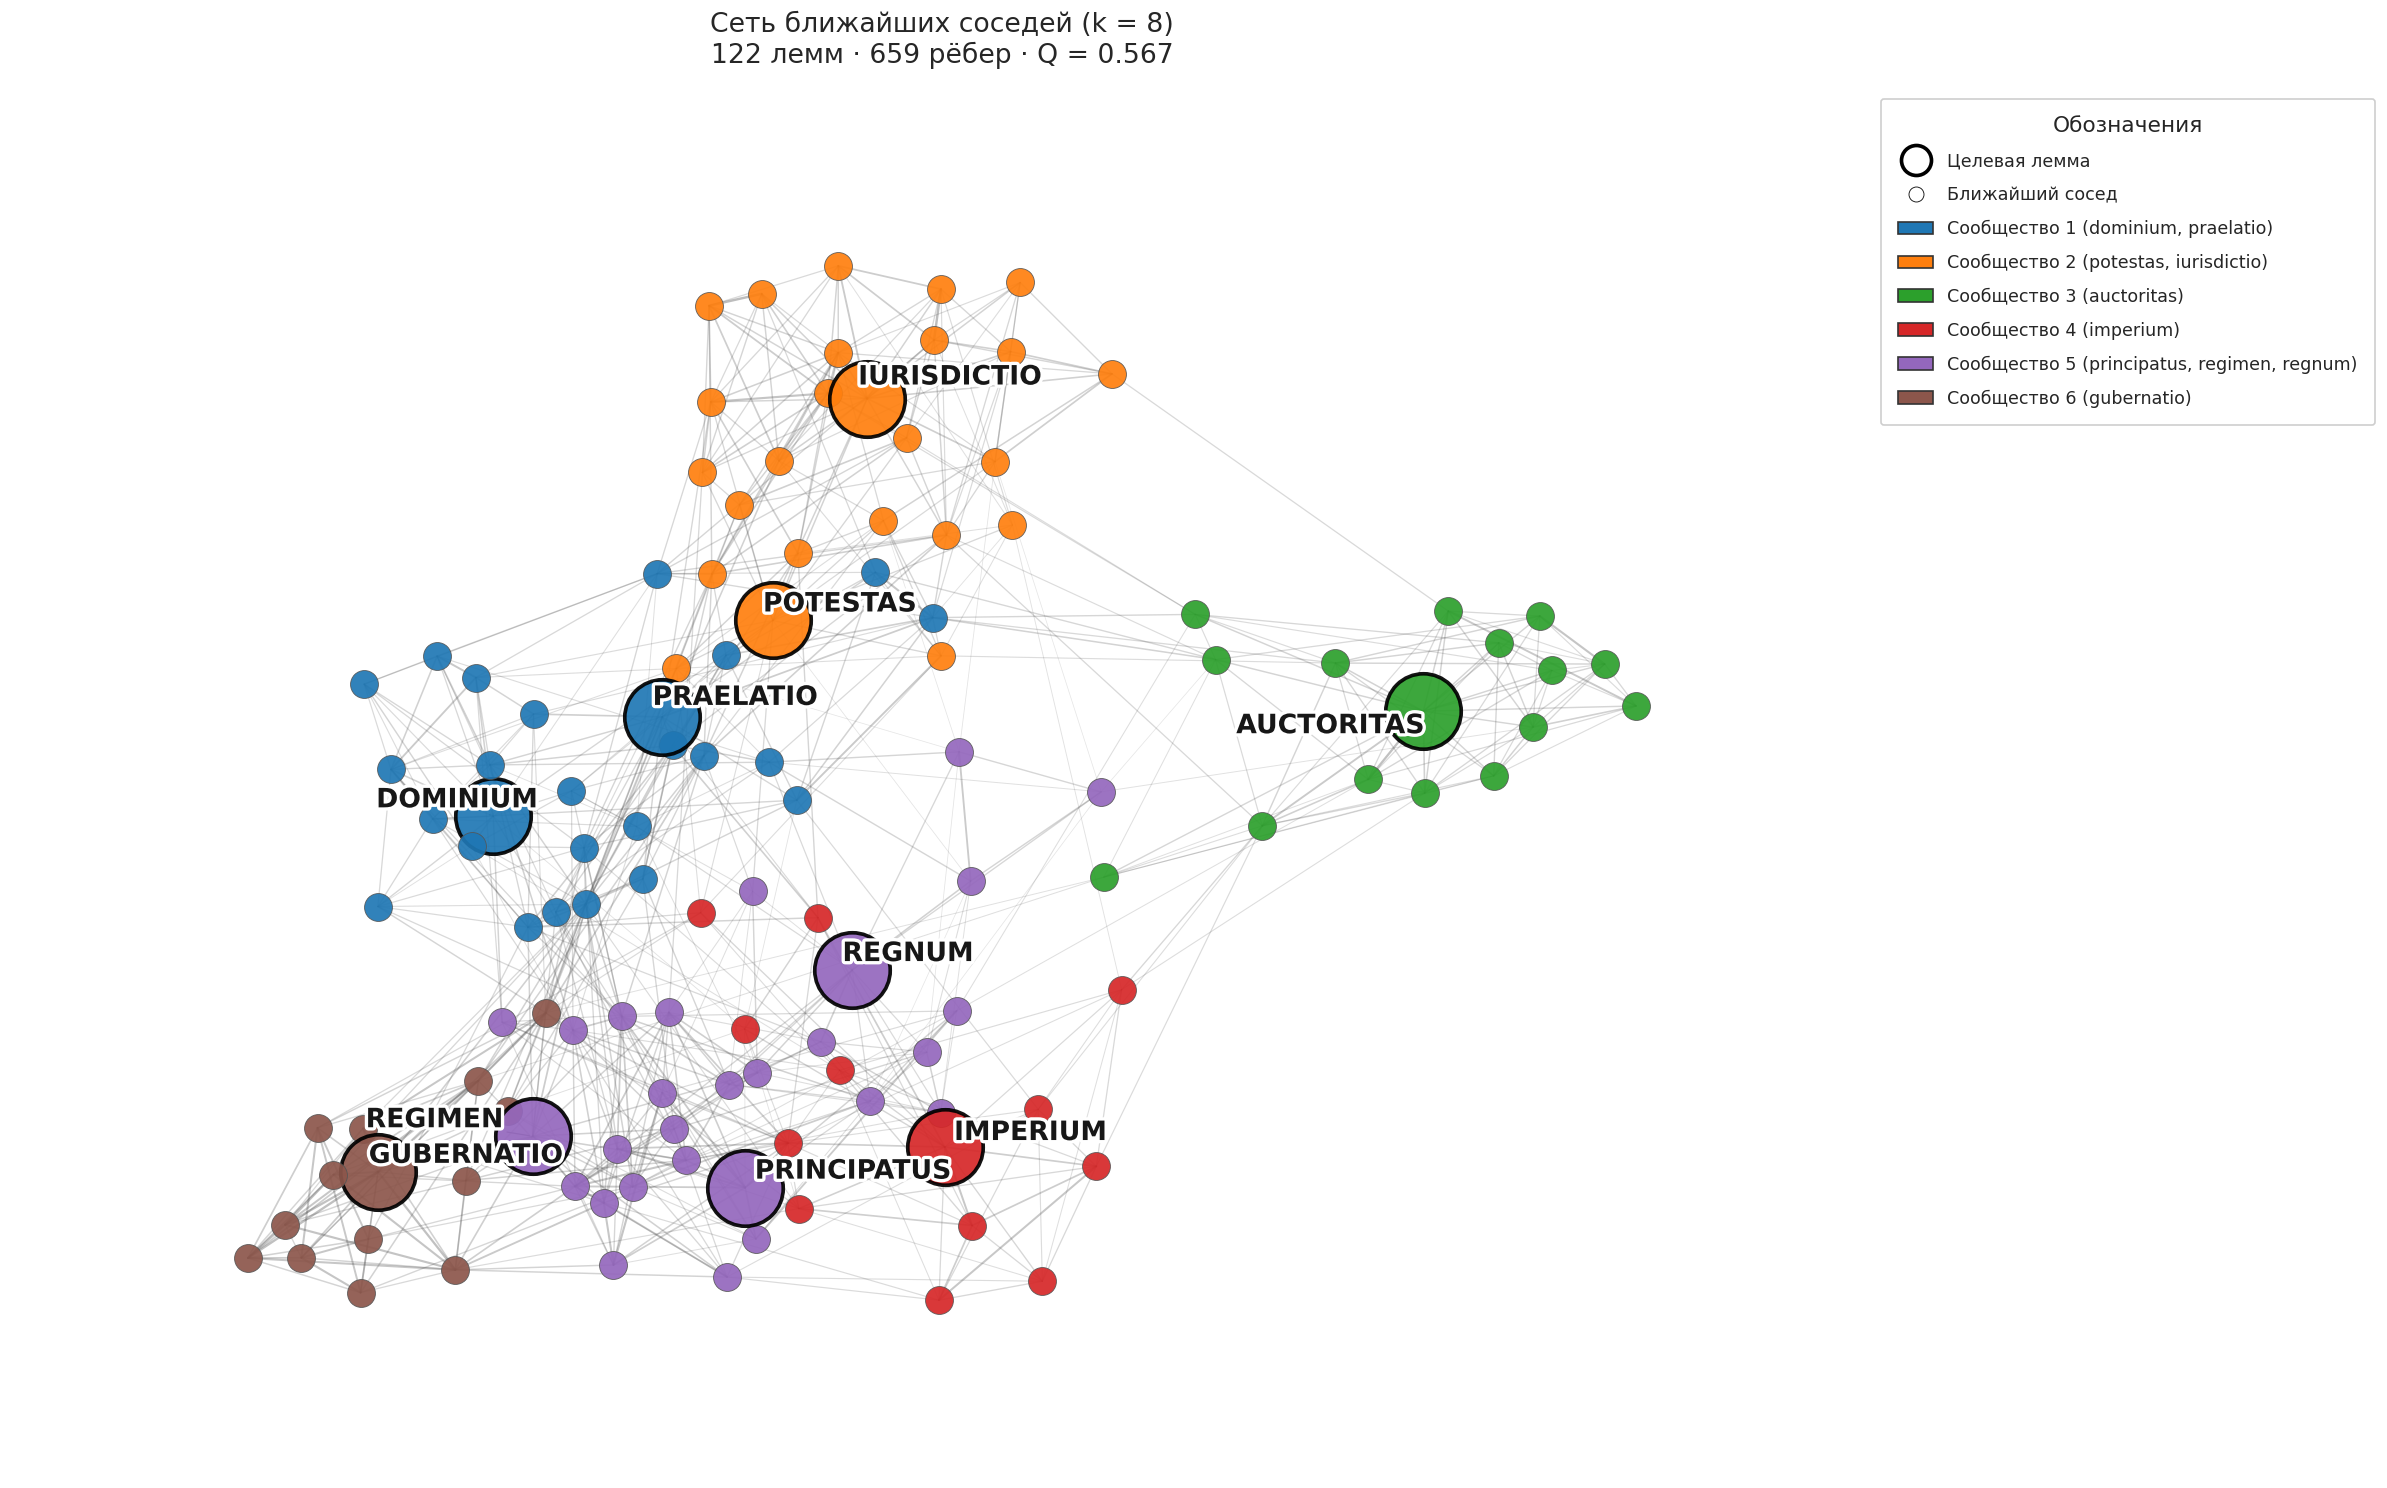

In [32]:
G_knn = build_knn_network(lemmas, similarity, KNN_K)
knn = analyse_network(G_knn)

shared = len({frozenset(e) for e in G.edges()} & {frozenset(e) for e in G_knn.edges()})
below = sum(d["weight"] < THRESHOLD for _, _, d in G_knn.edges(data=True))
print(f"Сеть ближайших соседей: {G_knn.number_of_edges()} рёбер "
      f"(в основной сети {G.number_of_edges()}); общих рёбер {shared}; "
      f"рёбер ниже порога θ = {THRESHOLD:.2f}: {below}")

save_table(pd.DataFrame([
    {"Лемма 1": u, "Лемма 2": v, "Косинусное сходство": float(d["weight"]),
     "Выбор взаимный": "да" if d["mutual"] else "нет"}
    for u, v, d in G_knn.edges(data=True)
]).set_index(["Лемма 1", "Лемма 2"]), "check_knn_edges")

fig = draw_network(G_knn, knn["membership"],
                   f"Сеть ближайших соседей (k = {KNN_K})\n"
                   f"{G_knn.number_of_nodes()} лемм · {G_knn.number_of_edges()} рёбер · Q = {knn['Q']:.3f}")
save_figure(fig, "check_knn_network", folder=os.path.join(FIG_DIR, "checks"))

### 14.2. Исключение редких лемм (частота ниже 10)

Из словаря основной сети удаляются нецелевые леммы, встречающиеся в обучающем корпусе менее десяти раз. Целевые леммы сохраняются. Новые соседи взамен удалённых не подбираются, порог не пересчитывается, веса оставшихся рёбер не меняются. Граница частоты служит ориентиром, а не критерием надёжности векторов.

In [33]:
removed = [w for w in lemmas if w not in TARGET_TERMS and freq(w) < MIN_FREQ]
kept = [w for w in lemmas if w not in removed]
keep_idx = [lemmas.index(w) for w in kept]
G_freq = build_network(kept, similarity[np.ix_(keep_idx, keep_idx)], THRESHOLD)
lowfreq = analyse_network(G_freq)
freq_membership = lowfreq["membership"]

ari = adjusted_rand_score([membership[w] for w in kept], [freq_membership[w] for w in kept])
print(f"Удалено {len(removed)} из {len(lemmas)} лемм; осталось {len(kept)} лемм и "
      f"{G_freq.number_of_edges()} рёбер; компонент {nx.number_connected_components(G_freq)}")
print(f"Скорректированный индекс Рэнда двух медоидных разбиений на {len(kept)} общих леммах: {ari:.3f}")

removed_table = pd.DataFrame([
    {"Лемма": w, "Частота": freq(w), "Сообщество в основной сети": membership[w],
     "Число связей в основной сети": int(G.degree(w))}
    for w in removed
]).sort_values(["Частота", "Лемма"]).set_index("Лемма")
display(Markdown("**Исключённые леммы**"))
display(removed_table)
save_table(removed_table, "check_lowfreq_removed")

freq_communities = pd.DataFrame([
    {"Сообщество": c,
     "Целевые леммы": ", ".join(t for t in TARGET_TERMS if freq_membership[t] == c),
     "Число лемм": sum(1 for w in kept if freq_membership[w] == c),
     "Все леммы сообщества": ", ".join(sorted(w for w in kept if freq_membership[w] == c))}
    for c in sorted(set(freq_membership.values()))
]).set_index("Сообщество")
display(Markdown("**Сообщества после исключения редких лемм (медоидное разбиение)**"))
display(freq_communities.style.set_properties(**{"text-align": "left", "white-space": "normal"}))
save_table(freq_communities, "check_lowfreq_communities")

# Сообщество praelatio: состав и связи каждой леммы внутри сообщества и во всей сети.
group = [w for w in kept if freq_membership[w] == freq_membership["praelatio"]]
inside = G_freq.subgraph(group)
praelatio_table = pd.DataFrame([
    {"Лемма": w, "Частота": freq(w), "Сообщество в основной сети": membership[w],
     "Связей внутри сообщества": int(inside.degree(w)),
     "Связей во всей сети": int(G_freq.degree(w)),
     "Косинусное сходство с praelatio": round(float(wv.similarity("praelatio", w)), 3)}
    for w in group
]).sort_values(["Связей внутри сообщества", "Лемма"], ascending=[False, True]).set_index("Лемма")
display(Markdown(f"**Сообщество *praelatio*: {len(group)} лемм, "
                 f"{inside.number_of_edges()} внутренних рёбер**"))
display(praelatio_table)
save_table(praelatio_table, "check_lowfreq_praelatio")

Удалено 20 из 122 лемм; осталось 102 лемм и 506 рёбер; компонент 1
Скорректированный индекс Рэнда двух медоидных разбиений на 102 общих леммах: 0.817


**Исключённые леммы**

,Частота,Сообщество в основной сети,Число связей в основной сети
Лемма,,,
assertiuus,5,3,9
auctoritatiuus,5,3,7
celatio,5,2,18
diaconatus,5,2,11
iurisconsultus,5,1,20
optimas,5,5,21
persuasibilis,5,4,3
plebeius,5,1,15
declaratio,6,3,6


**Сообщества после исключения редких лемм (медоидное разбиение)**

,Целевые леммы,Число лемм,Все леммы сообщества
Сообщество,,,
1,dominium,10,"coerceo, conseruus, dominium, dominor, latrocinium, seruitium, seruitus, seruus, subiectio, usurpo"
2,"potestas, iurisdictio",20,"absolutio, arbiter, clauis, degrado, ecclesia, episcopatus, episcopus, excommunicatio, excommunico, eximo, forum, indulgentia, inuincibilis, iurisdictio, laicus, minister, parochialis, patrimonium, potestas, sacerdotalis"
3,praelatio,11,"is, iudiciarius, officium, ordinarius, possum, praefero, praeficio, praelatio, praepono, primatus, procuratio"
4,auctoritas,10,"aio, apostolicus, auctor, auctoritas, ceterum, expositio, induco, obiectio, probatio, solutio"
5,imperium,9,"elicitiuus, exequor, imperatiuus, imperium, impero, motiuus, nutus, obedio, uis"
6,"principatus, regimen",19,"archangelus, ciuitas, despoticus, dominatio, dominatiuus, michael, persa, princeps, principatus, principor, prouincia, rector, regalis, regimen, regitiuus, regius, regnatiuus, rex, tyrannicus"
7,gubernatio,14,"coordinatio, gubernatio, gubernator, gubernatorius, guberno, ordinatio, ordinator, praesideo, prouidentia, prouidus, prouisio, prouisor, subdo, subiaceo"
8,regnum,9,"aperio, iechonias, ierusalem, introeo, introitus, intromitto, possideo, regno, regnum"


**Сообщество *praelatio*: 11 лемм, 32 внутренних рёбер**

,Частота,Сообщество в основной сети,Связей внутри сообщества,Связей во всей сети,Косинусное сходство с praelatio
Лемма,,,,,
praefero,821,2,8,16,0.671
praeficio,23,6,8,36,0.655
praelatio,249,2,8,17,1.000
officium,940,2,7,16,0.638
ordinarius,32,2,7,16,0.648
praepono,99,5,7,17,0.654
procuratio,10,2,7,8,0.632
is,38949,2,6,10,0.631
primatus,18,5,4,13,0.634


### 14.3. Сопоставление трёх сетей

Сводная таблица сравнивает основную сеть, сеть ближайших соседей и сеть без редких лемм. Для каждой из 45 пар целевых лемм приводится число запусков из 50, в которых пара попала в одно сообщество. Модулярность разных графов напрямую не сопоставима.

,Узлов,Рёбер,Компонент,Сообществ медоида,Модулярность Q медоида
Сеть,,,,,
Основная сеть,122,715,1,7,0.4945
Ближайшие соседи (k = 8),122,659,1,6,0.5674
Без редких лемм (частота ≥ 10),102,506,1,8,0.4838


**Сообщества целевых лемм в трёх сетях (номера внутри каждой сети свои)**

,Частота,Основная сеть,Ближайшие соседи (k = 8),Без редких лемм (частота ≥ 10)
Лемма,,,,
dominium,287,1,1,1
potestas,2527,2,2,2
praelatio,249,2,1,3
iurisdictio,97,2,2,2
auctoritas,1363,3,3,4
imperium,449,4,4,5
principatus,160,5,5,6
regimen,189,5,5,6
gubernatio,248,6,6,7


**Пары, которые хотя бы в одной сети попадали в одно сообщество (из 50 запусков)**

,Основная сеть,Ближайшие соседи (k = 8),Без редких лемм (частота ≥ 10)
Пара,,,
dominium – praelatio,2,48,0
dominium – principatus,1,0,0
potestas – praelatio,46,2,3
potestas – iurisdictio,50,49,50
praelatio – iurisdictio,46,1,3
praelatio – regimen,0,0,1
praelatio – gubernatio,0,0,2
principatus – regimen,49,45,49
principatus – gubernatio,5,0,0


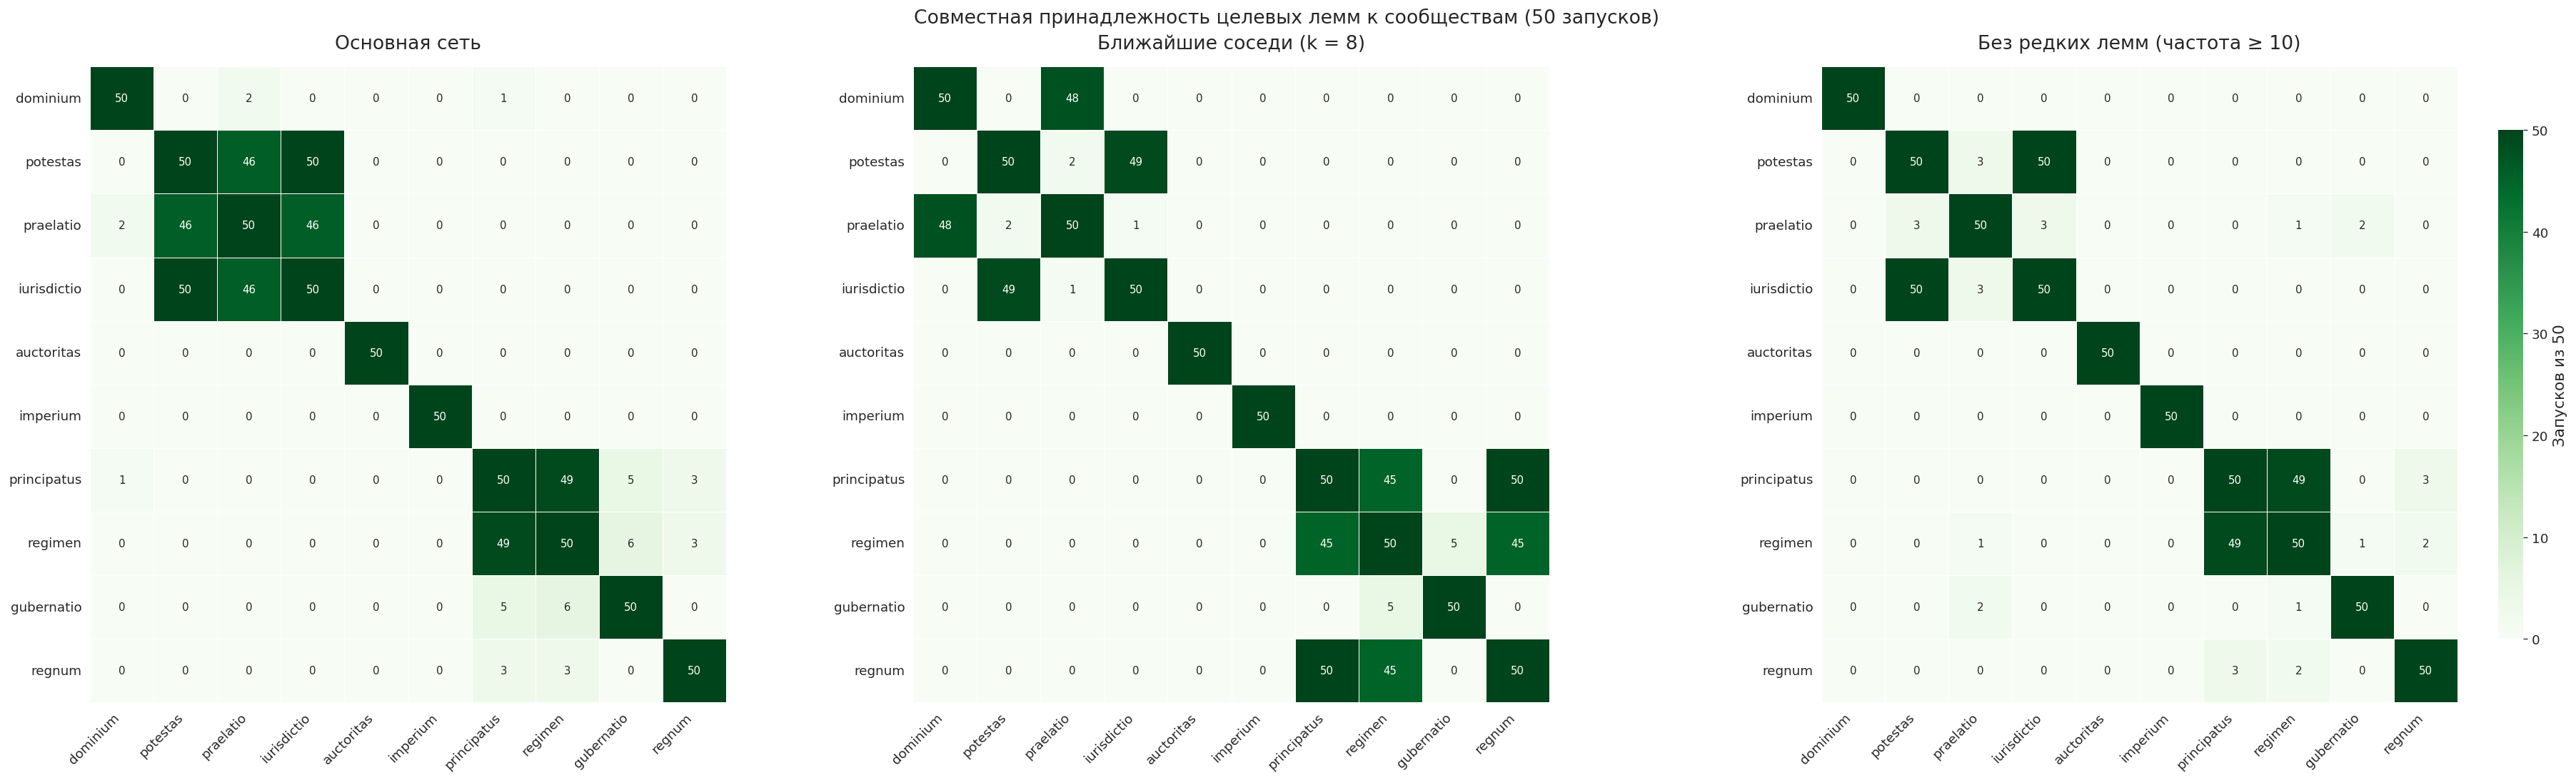

In [34]:
CHECKS = {"Основная сеть": main, f"Ближайшие соседи (k = {KNN_K})": knn,
          f"Без редких лемм (частота ≥ {MIN_FREQ})": lowfreq}

check_networks = pd.DataFrame([
    {"Сеть": name, "Узлов": r["graph"].number_of_nodes(), "Рёбер": r["graph"].number_of_edges(),
     "Компонент": nx.number_connected_components(r["graph"]),
     "Сообществ медоида": len(set(r["membership"].values())),
     "Модулярность Q медоида": round(r["Q"], 4)}
    for name, r in CHECKS.items()
]).set_index("Сеть")
display(check_networks)
save_table(check_networks, "check_networks")

check_targets = pd.DataFrame(
    {name: [r["membership"][t] for t in TARGET_TERMS] for name, r in CHECKS.items()},
    index=TARGET_TERMS).rename_axis("Лемма")
check_targets.insert(0, "Частота", [freq(t) for t in TARGET_TERMS])
display(Markdown("**Сообщества целевых лемм в трёх сетях (номера внутри каждой сети свои)**"))
display(check_targets)
save_table(check_targets, "check_target_communities")

check_pairs = pd.DataFrame(
    {name: [int(r["together"].loc[a, b]) for a, b in TARGET_PAIRS] for name, r in CHECKS.items()},
    index=[f"{a} – {b}" for a, b in TARGET_PAIRS]).rename_axis("Пара")
display(Markdown(f"**Пары, которые хотя бы в одной сети попадали в одно сообщество (из {N_LEIDEN_RUNS} запусков)**"))
display(check_pairs.loc[check_pairs.sum(axis=1) > 0])
save_table(check_pairs, "check_target_pairs")

fig, axes = plt.subplots(1, 3, figsize=(30, 9), constrained_layout=True)
for ax, (name, r) in zip(axes, CHECKS.items()):
    draw_co_membership(r["together"], order, name, ax=ax, colorbar=(ax is axes[-1]))
fig.suptitle(f"Совместная принадлежность целевых лемм к сообществам ({N_LEIDEN_RUNS} запусков)",
             fontsize=TITLE_SIZE)
save_figure(fig, "check_co_membership", folder=os.path.join(FIG_DIR, "checks"))

### 14.4. Иерархическая кластеризация целевых лемм

Группируются только десять целевых векторов, без остального словаря и без сети. Расстояние — косинусное (1 − сходство), способ объединения — средняя связь. Число групп заранее не задаётся. Дендрограмма показывает прямую близость векторов, а сеть — положение слов среди связей всего словаря, поэтому результаты могут расходиться.

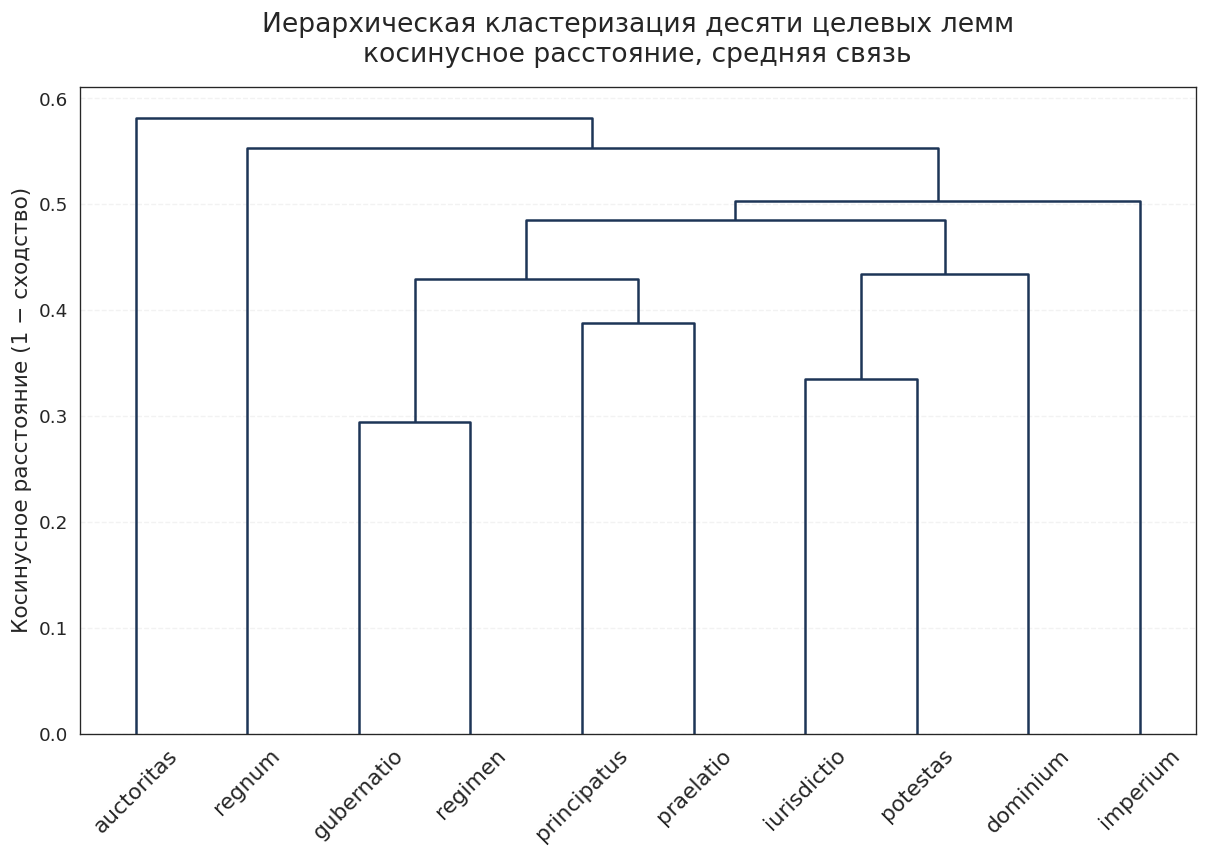

**Порядок объединения целевых лемм**

,Группа 1,Группа 2,Косинусное расстояние,Лемм в объединении
Шаг,,,,
1,gubernatio,regimen,0.2945,2
2,iurisdictio,potestas,0.3349,2
3,principatus,praelatio,0.3882,2
4,"gubernatio, regimen","principatus, praelatio",0.4296,4
5,"iurisdictio, potestas",dominium,0.4337,3
6,"gubernatio, regimen, principatus, praelatio","iurisdictio, potestas, dominium",0.4854,7
7,"gubernatio, regimen, principatus, praelatio, i...",imperium,0.5034,8
8,regnum,"gubernatio, regimen, principatus, praelatio, i...",0.5535,9
9,auctoritas,"regnum, gubernatio, regimen, principatus, prae...",0.5818,10


In [35]:
target_vectors = np.array([wv[t] for t in TARGET_TERMS], dtype=np.float64)
Z = linkage(pdist(target_vectors, metric="cosine"), method="average", optimal_ordering=True)

fig, ax = plt.subplots(figsize=(12, 7))
dendrogram(Z, labels=TARGET_TERMS, leaf_rotation=45, leaf_font_size=13,
           color_threshold=0, above_threshold_color="#1d3557", ax=ax)
ax.set_title("Иерархическая кластеризация десяти целевых лемм\n"
             "косинусное расстояние, средняя связь", pad=15)
ax.set_ylabel("Косинусное расстояние (1 − сходство)")
ax.grid(axis="y", linestyle="--", alpha=0.25)
save_figure(fig, "check_dendrogram", folder=os.path.join(FIG_DIR, "checks"))

groups = {i: [term] for i, term in enumerate(TARGET_TERMS)}
merges = []
for step, (a, b, distance, size) in enumerate(Z, start=1):
    a, b = int(a), int(b)
    merges.append({"Шаг": step, "Группа 1": ", ".join(groups[a]), "Группа 2": ", ".join(groups[b]),
                   "Косинусное расстояние": round(float(distance), 4), "Лемм в объединении": int(size)})
    groups[len(TARGET_TERMS) + step - 1] = groups[a] + groups[b]
merge_table = pd.DataFrame(merges).set_index("Шаг")
display(Markdown("**Порядок объединения целевых лемм**"))
display(merge_table)
save_table(merge_table, "check_dendrogram_merges")

## 15. Сводка и ограничения

In [36]:
summary = pd.Series({
    "Целевых лемм": len(TARGET_TERMS),
    "Соседей на целевую лемму (N)": TOP_N,
    "Лемм в основной сети": G.number_of_nodes(),
    "Рёбер в основной сети": G.number_of_edges(),
    "Порог θ": THRESHOLD,
    "Сообществ в медоидном разбиении": len(communities),
    "Модулярность Q медоида": round(Q, 4),
    "Номер запуска медоида": main["medoid_seed"],
    "Среднее расхождение медоида с остальными запусками": round(main["medoid_distance"], 5),
    "Запусков Лейдена": N_LEIDEN_RUNS,
    f"Сеть ближайших соседей (k = {KNN_K}): рёбер": G_knn.number_of_edges(),
    f"Лемм с частотой ниже {MIN_FREQ}, исключённых при проверке": len(removed),
    "Индекс Рэнда (основная сеть и сеть без редких лемм)": round(float(ari), 4),
}, name="Значение").rename_axis("Показатель")
display(summary.to_frame())
save_table(summary.to_frame(), "analysis_summary")

,Значение
Показатель,
Целевых лемм,10.00000
Соседей на целевую лемму (N),15.00000
Лемм в основной сети,122.00000
Рёбер в основной сети,715.00000
Порог θ,0.59000
Сообществ в медоидном разбиении,7.00000
Модулярность Q медоида,0.49450
Номер запуска медоида,0.00000
Среднее расхождение медоида с остальными запусками,0.01334


**Что показывают расчёты.** Косинусное сходство характеризует близость контекстов, в которых леммы употребляются в корпусе, по данным одной модели. Сообщества описывают строение построенной сети и не совпадают ни со значениями слов, ни с понятиями автора.

**Что проверено.** Зависимость разбиения от случайной инициализации алгоритма (50 запусков), от числа соседей (10, 15, 20), от порога (повышение на 0,01), от правила отбора рёбер (ближайшие соседи вместо порога) и от редких лемм (исключение лемм с частотой ниже 10).

**Что не проверено.** Модель не обучалась заново, поэтому устойчивость самих векторов к повторному обучению не оценивается. Один вектор соответствует всем употреблениям леммы, включая цитаты; разные значения слова не разделяются.

**Выходные файлы.** Таблицы — в `tables/`; рисунки — в `figures/` (основная сеть, матрицы, распределение сходства, выбор порога), `figures/communities/` (графы сообществ), `figures/local_networks/` (локальные сети) и `figures/checks/` (дополнительные проверки). Описание файлов дано в `README.md`.